<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/BruteForceRE_TranspiledQNN_Ghosh2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reverse engineering of transpiled QML models: Ghosh & Ghosh (2024) step by step

This notebook re-implements, runs and checks the attack of

> Archisman Ghosh and Swaroop Ghosh, "The Quantum Imitation Game: Reverse Engineering of Quantum Machine Learning Models", ACM, 2024
> (arXiv:2407.07237 [quant-ph], v2 15 Jul 2024). https://doi.org/10.1145/3689939.3695783

The paper publishes no code. Everything below is written from the method as the paper describes it.

**What the notebook does.** A user trains a small quantum classifier (PennyLane, MNIST), transpiles it for a cloud quantum computer (Qiskit, linear coupling map, basis gates
`id, x, sx, cx, rz`) and sends it to an *untrusted vendor*. Transpilation melts every run of single-qubit rotations (for example `RX(a) RY(b) RZ(c)`) into the hardware pattern
`RZ SX RZ SX RZ`, so the vendor sees different numbers than the user trained. The vendor wants the original rotation angles back (to re-transpile the model for other hardware, resell it,
train it further or strip a watermark). The paper's attack: (1) read the entanglement off the `CX` gates, (2) recognise, with a **look-up table (LUT)** of basic transpilations, which rotation
template produced each transpiled block, and (3) find the angles by **exhaustive (brute-force) search** over a grid on [-pi, pi]: re-transpile every candidate and keep the one whose transpiled angles
match. We (a) re-draw and verify the LUT (Fig. 5) with the real Qiskit transpiler, (b) implement Algorithm 1 and check the search against a literal "transpile every candidate" version, (c) train the ten
classifiers of Table 1 on MNIST, steal them and measure the parameter error and the accuracy loss, (d) redo the step-size study of Table 2 and the time studies of Fig. 8 and Table 3, and (e) implement
and measure the paper's countermeasure (fixed dummy rotations on extra layers and qubits, Fig. 9-12 and Table 4).

**How to run it.** Google Colab, CPU runtime, *Runtime > Run all*. As committed, `FAST_MODE = False`: the outputs below come from the full run (two seeds, 40 training epochs, step sizes searched down to 0.02, layers up to 16, up to 8 dummy layers/qubits), which took about 48 minutes on a shared 8-core CPU (Colab's free CPU runtime needs roughly 1-1.5 h).
Set `FAST_MODE = True` in the configuration cell for a class demo of roughly 10-12 minutes (one seed, 12 training epochs, step sizes down to 0.05); its classifiers are weaker, which makes the accuracy columns noisier. The budgets of both modes are listed in the configuration cell.

**What you get at the end.** The re-drawn Fig. 5 (transpilation look-up table), Figs. 6-7 (original, transpiled and reverse-engineered circuits), Table 1 (ten classifiers: parameter error, accuracy loss),
Table 2 (step size against error and time), Fig. 8 and Table 3 (time against qubits and layers), Fig. 12 and Table 4 (countermeasure: overhead for the attacker and cost for the user), a verdict for every claim of the
paper and a critical reading, including two measurable weaknesses of the countermeasure.

## The paper in one page

**Problem.** Trained QML circuits are valuable intellectual property: quantum hardware time is expensive and scarce. A user compiles the trained model for the cloud provider's hardware, so the provider
(or a malicious insider) holds the *transpiled* circuit in white-box form. Using it as it is, on the same hardware, is easy (strip the data-encoding part and attach new data). The paper asks for more: recover the
**pre-transpilation model**, i.e. the entanglement structure *and the trained rotation angles*, so that the model can be re-transpiled for other hardware, sold, trained further, or have its watermark altered.

**Why the angles are hard to get.** (i) All rotations become `RZ` and `SX`; (ii) consecutive rotations from different gates are merged into one block `RZ SX RZ SX RZ`; (iii) a global phase appears;
(iv) a higher optimisation level merges even more. The entanglement is easy: `CX` is a basis gate, `CY` and `CZ` become `CX` with fixed single-qubit gates around it, and a `SWAP` inserted by routing is a triple of `CX`.

**Threat model.** The vendor is "honest but curious": white-box access to the transpiled circuit and to the transpiler (to check guesses), lots of compute, no noise considerations (trained parameters are already fixed).

**Method (Algorithm 1).** Parse the transpiled circuit qubit by qubit; split it at `CX` gates; look each block up in the LUT of Fig. 5 (which template of `RX`, `RY`, `RZ` produces this gate pattern?); search the parameters
of the template by brute force on a grid of step `N` in [-pi, pi]: transpile every candidate and keep the one with the smallest difference of transpiled parameters. Cost `O(k^(2 pi / N))` for `k` parameters per block.
Several consecutive rotations of one block are reported as the shorter set `RX(phi1) RY(phi2) RZ(phi3)`, so the reverse-engineered circuit has the same function and often fewer parameters.

**Experiments.** QNN classifiers on MNIST (PennyLane `lightning.qubit`, gradient descent, learning rate 0.05, MSE; Qiskit transpiler with linear coupling map and basis `[id, x, sx, cnot, rz]`): Examples 1 and 2 (1-qubit and
2-qubit classifier), Table 1 (ten classifiers of 1, 2, 4, 8 qubits and 1-3 layers: mean and SD of the parameter error 5.3e-2 ... 1.7e-1, accuracy error 1e-16 ... 7.6 %), Table 2 (step 0.1 / 0.01 / 0.001: 51 s / 662 s / 8.5e5 s,
error 5.9e-2 / 3.7e-3 / 5.0e-4), Fig. 8 and Table 3 (time grows with qubits and layers, up to above 1e7 s), and the **countermeasure**: add dummy rotations with fixed parameters (extra layers, extra qubits, both) that transpile
like trained ones; 2 dummy qubits and 2 dummy layers give an overhead of ~1.76x for a 2-qubit 3-layer classifier at a performance cost below 9 % (Table 4: 8.76 / 7.01 / 3.53 %).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | PennyLane (`lightning.qubit`) for training, Qiskit for transpilation | same split. A PennyLane `default.qubit` QNode defines, draws and evaluates the circuits; the gradient-descent loops run on an equivalent PyTorch state-vector simulator (`FastSim`) that is **asserted equal** to the QNode for every trained model |
| Training | gradient descent, learning rate 0.05, MSE, MNIST "picking labels as per the capacity of the QML model" | mini-batch gradient descent (`theta <- theta - 0.05 grad`), MSE between the class probabilities and one-hot labels; binary task, digits 3 vs 5, read-out = probability of qubit 0 for every classifier (`# CHOICE`; a harder pair than 0 vs 1, accuracies near the paper's 70 %); `N_TRAIN` balanced images, `EPOCHS` epochs (`# CHOICE`, not stated) |
| Pre-processing | not stated | pixels / 255, `PCA(n_qubits)`, `MinMaxScaler((0, pi))`, `RY(x_i)` angle encoding on qubit *i* (paper Fig. 4); every transform fitted on the training split only |
| Classifier layer | Table 1 lists qubits, layers and #parameters (4, 6, 12, 18, 8, 16, 24, 16, 32, 48); Fig. 7 shows `RZ RX RY` per qubit for 2 qubits | one *layer* = a rotation block on every qubit, then a chain of `CX` gates. 1 qubit: the 4-gate circuit of Fig. 6 (`RX RY RX RY`, 4 parameters); 2 qubits: `RZ RX RY` per qubit (3 per qubit and layer: 6, 12, 18); 4 and 8 qubits: `RZ RX` per qubit (2 per qubit and layer: 8, 16, 24 and 16, 32, 48; `RZ` first because an `RZ` right before the `CX` chain would not change any measured probability, `# CHOICE`) |
| Entangler | `CNOT`/`CY`/`CZ` cascades (Sec. IV-A), not drawn for the classifiers | `CX(n-1,n-2) ... CX(1,0)` (`# CHOICE`): neighbours on a line (no `SWAP`), and every qubit can influence qubit 0, which is read out. The opposite direction would leave qubits 2... without influence on the read-out |
| Transpilation | Qiskit transpiler, linear coupling map, basis `[id, x, sx, cnot, rz]`, optimisation level 1 (Fig. 5 caption) | `transpile(..., coupling_map=line, basis_gates=[id,x,sx,cx,rz], optimization_level=1, seed_transpiler=SEED)`. The state-embedding gates are removed before transpilation: the adversary "strips off the state embedding" (Sec. V-B) |
| LUT | Fig. 5: RX, RY, RZ, stacked rotations, a general product; CY, CZ | two entries are enough for the classifiers: last transpiled `RZ` = +-pi/2 means `RZ` then `RX` (template `zx`, 2 parameters); otherwise a general product (template `xyz`, 3 parameters). Fig. 5 is re-drawn and every identity is checked |
| Search | brute force over [-pi, pi] with step `N`; re-transpile every candidate; closest transpiled parameters | the same grid `-pi, -pi + N, ...`, candidate score = sum of absolute (circular) differences of the three transpiled `RZ` angles. The candidates are scored with a **vectorised copy** of Qiskit's Euler (ZSX) decomposition that is asserted equal to `qiskit.transpile`; a **literal** search that really transpiles every candidate is run on a coarse grid and gives the identical answer |
| Time | wall-clock time of the authors' implementation (51 s ... 1e7 s) | two numbers per experiment: the **measured** time of the vectorised search, and the time the literal search *would* take = (candidates) x (measured time of one `qiskit.transpile` call). Both are labelled; the paper's absolute seconds depend on its (unpublished) implementation and machine |
| Parameter error | "difference in the parameters of the transpiled circuit of the user-designed model and of the reverse-engineered circuit" (Sec. V-C) | exactly that: mean and SD of the circular difference of the transpiled `RZ` angles, pooled over all parameters of all seeds. The error measured on the *original* angles is not meaningful because the angles of a block are not unique |
| Accuracy error | "percentage decrease in the testing accuracy" | `(acc_original - acc_reverse_engineered) / acc_original * 100` on the held-out test images (the examples of Sec. V-B quote training accuracy; both are printed) |
| Countermeasure | Figs. 9-11: fixed `RX/RY` rotations on every qubit as an extra layer (4 fixed parameters on 2 qubits), an extra qubit with 3 fixed rotations, or both (13 parameters to recover instead of 6) | extra layer = fixed `RX RY` on every trained qubit **followed by the CX chain**; dummy qubit = one fixed `RX RY RX` block at the top of the chain, joined into every layer's chain; fixed angles drawn once from `U(-pi, pi)` (`# CHOICE`). The modified model is retrained with the fixed rotations frozen |
| Seeds / budgets | one run per entry, no seeds | `FAST_MODE`: 1 seed; full run: 2 seeds (mean +- SD over the pooled parameters) |
| Hardware | none (noiseless simulation) | none; `IBM_TOKEN` is unused |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("qiskit", "pennylane", "torch", "huggingface_hub", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "qiskit==2.5.2" "pennylane==0.45.1" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages already present; skipping pip install.")

All packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in about 10 minutes. False: the full run (more seeds, finer step sizes, longer training).
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # unused: the paper is a noiseless simulation study (kept for the project convention)
DATA_DIR  = "data"          # cache for the MNIST download (relative to the working directory)
DIGITS    = [3, 5]          # CHOICE: binary task, MNIST digits 3 vs 5 ("labels as per the capacity of the model"); harder than 0 vs 1, so accuracies are in the paper's 60-70 % range

# ---- paper settings (kept in both modes) ----
BASIS_GATES = ["id", "x", "sx", "cx", "rz"]   # paper Sec. IV: basis gate set [id, x, sx, cnot, rz]
OPT_LEVEL   = 1                               # paper Fig. 5: optimisation level 1
BRUTE_STEP  = 0.1                             # paper: brute-force step size N = 0.1 (Table 1, Fig. 8); Table 2 sweeps it
QML_LR      = 0.05                            # paper Sec. V-A: gradient descent, learning rate 0.05, MSE loss
CHUNK       = 1_000_000                       # candidates evaluated per numpy chunk of the exhaustive search (keeps memory small)

# ---- budgets that depend on the mode ----
if FAST_MODE:
    N_TRAIN, N_TEST, BS, EPOCHS = 240, 300, 40, 12
    SEEDS        = [SEED]
    STEP_SWEEP   = [0.4, 0.2, 0.1, 0.05]        # Table 2: step sizes that are searched for real (the paper: 0.1, 0.01, 0.001)
    N_STEP_BLOCKS = 10                          # random blocks averaged per step size (Table 2 error column)
    LITERAL_STEP = 0.8                          # step of the literal "re-transpile every candidate" search (section 6)
    N_TIMING     = 20                           # qiskit.transpile calls timed to project the brute-force time
    LAYER_SWEEP  = [1, 2, 3, 4]                 # Table 3: layers of the 4-qubit classifier
    QUBIT_SWEEP  = [1, 2, 4, 8]                 # Fig. 8: classifier width (3 layers)
    CM_SWEEP     = [1, 2, 4]                    # Fig. 12: number of dummy layers / dummy qubits
else:
    N_TRAIN, N_TEST, BS, EPOCHS = 400, 400, 40, 40
    SEEDS        = [SEED, SEED + 1]
    STEP_SWEEP   = [0.4, 0.2, 0.1, 0.05, 0.02]            # 0.01 (2.5e8 candidates, ~20 min per block) is extrapolated, not run
    N_STEP_BLOCKS = 20
    LITERAL_STEP = 0.4
    N_TIMING     = 100
    LAYER_SWEEP  = [1, 2, 4, 8, 16]
    QUBIT_SWEEP  = [1, 2, 4, 8]
    CM_SWEEP     = [1, 2, 4, 8]
print(f"FAST_MODE={FAST_MODE}  seeds {SEEDS}  step sweep {STEP_SWEEP}  classifier epochs {EPOCHS}")

FAST_MODE=False  seeds [42, 43]  step sweep [0.4, 0.2, 0.1, 0.05, 0.02]  classifier epochs 40


In [3]:
import os, io, time, math, warnings, functools, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import qiskit, pennylane as qml, sklearn, torch
from pennylane import numpy as pnp
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator
from qiskit.transpiler import CouplingMap
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

rng = np.random.default_rng(SEED)
pnp.random.seed(SEED)
torch.manual_seed(SEED); torch.set_num_threads(max(1, min(4, os.cpu_count() or 2)))
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
print("qiskit", qiskit.__version__, "| pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
T_START = time.time()

qiskit 2.5.2 | pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. What the vendor sees: the look-up table of transpilations (paper Sec. II-B, IV, Fig. 5)

On IBM hardware the native gates are `id, x, sx, cx, rz`. A run of single-qubit rotations on one qubit is multiplied into one 2x2 unitary and re-synthesised as
`RZ(phi0) SX RZ(phi1) SX RZ(phi2)` plus a global phase the hardware ignores (Euler "ZSX" decomposition). The paper's adversary builds a **look-up table** from basic transpilations (Fig. 5) and uses it to decide which
combination of `RX`, `RY`, `RZ` produced a transpiled block. The cells below draw the cases of Fig. 5 with the real Qiskit transpiler and then **verify every identity the paper states** on random angles, so that
the attack below rests on checked facts. The last cell **builds a vectorised copy of the decomposition**, in numpy, to score hundreds of thousands of candidate angle triples per second, and asserts that it gives the same angles as `qiskit.transpile`.

In [4]:
def wrap(a):
    """Map angles to (-pi, pi]; a 2*pi shift of an RZ changes only the global phase."""
    return (a + np.pi) % (2 * np.pi) - np.pi

def vendor_transpile(qc, seed=SEED, level=OPT_LEVEL, coupling_map="line"):
    """The untrusted vendor's transpiler: IBM basis gates, linear coupling map, trivial initial layout (paper Sec. IV / Fig. 5)."""
    n = qc.num_qubits
    cm = CouplingMap.from_line(n) if (coupling_map == "line" and n > 1) else coupling_map if coupling_map != "line" else None
    return transpile(qc, basis_gates=BASIS_GATES, coupling_map=cm, optimization_level=level,
                     initial_layout=list(range(n)) if cm is not None else None, seed_transpiler=seed)

def gate_names(qc):
    return [i.operation.name for i in qc.data]

def rz_angles(qc):
    return [float(i.operation.params[0]) for i in qc.data if i.operation.name == "rz"]

def same_up_to_phase(U, V, tol=1e-9):
    """True if two unitaries are equal up to a global phase."""
    return abs(np.trace(np.conj(U).T @ V)) / U.shape[0] > 1 - tol

def rot_np(g, t):
    """Batch of single-qubit rotations RX/RY/RZ(t) as (N,2,2) complex matrices."""
    t = np.asarray(t, dtype=float)
    c, s = np.cos(t / 2), np.sin(t / 2)
    z = np.zeros_like(t, dtype=complex)
    if g == "x":   m = [[c + 0j, -1j * s], [-1j * s, c + 0j]]
    elif g == "y": m = [[c + 0j, -s + 0j], [s + 0j, c + 0j]]
    else:          m = [[np.exp(-1j * t / 2), z], [z, np.exp(1j * t / 2)]]
    m = np.array(m)
    return m.transpose(2, 0, 1) if t.ndim > 0 else m

def seq_unitary(seq, th):
    """Unitary of the single-qubit gate sequence `seq` ('xyz' = RX first, then RY, then RZ); th has shape (N, len(seq))."""
    th = np.atleast_2d(th); U = None
    for j, g in enumerate(seq):
        R = rot_np(g, th[:, j]); U = R if U is None else R @ U
    return U

def zsx_params(U):
    """Vectorised copy of Qiskit's ZSX Euler decomposition: the three RZ angles (time order) of RZ SX RZ SX RZ."""
    det = np.linalg.det(U); da = np.angle(det)
    theta = 2 * np.arctan2(np.abs(U[:, 1, 0]), np.abs(U[:, 0, 0]))
    a1 = np.angle(U[:, 1, 1]); a2 = np.angle(U[:, 1, 0])
    phi = a1 + a2 - da; lam = a1 - a2
    return np.stack([wrap(lam), wrap(theta + np.pi), wrap(phi + np.pi)], 1)

def template_circuit(seq, th):
    qc = QuantumCircuit(1)
    for g, t in zip(seq, th):
        getattr(qc, "r" + g)(float(t), 0)
    return qc

def block_phis(qc_t):
    """Three RZ angles (time order) of a transpiled one-qubit block; shorter patterns (e.g. a lone RY) are canonicalised through the block's unitary."""
    if gate_names(qc_t) == ["rz", "sx", "rz", "sx", "rz"]:
        return np.array(rz_angles(qc_t))
    return zsx_params(Operator(qc_t).data[None])[0]

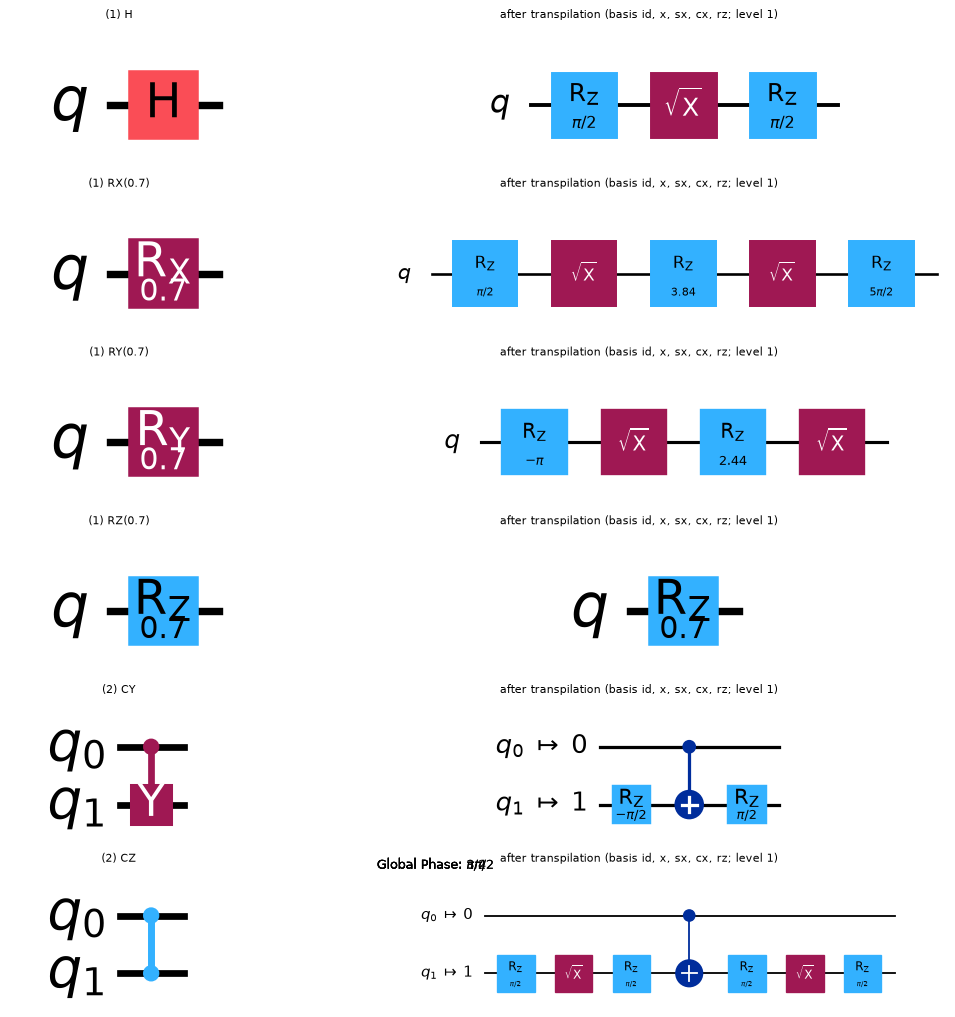

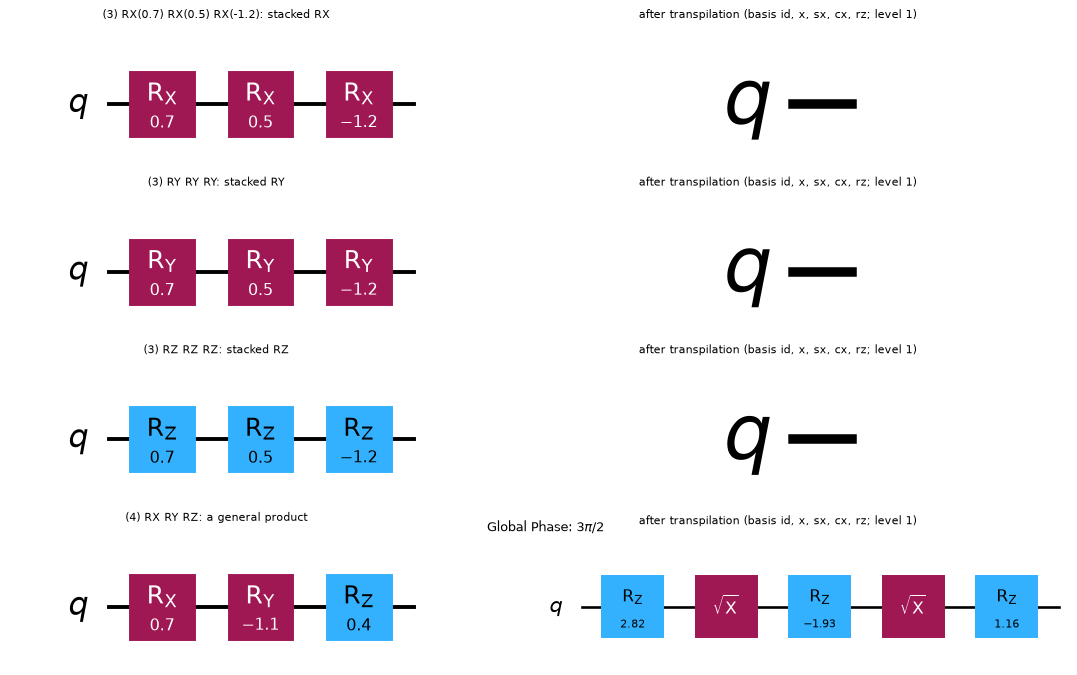

In [5]:
# ---- Fig. 5 re-drawn with the real Qiskit transpiler: original circuit (left) and what the vendor sees (right) ----
def draw_pairs(cases, ncols=2, w=13, h=1.9):
    fig, axes = plt.subplots(len(cases), 2, figsize=(w, h * len(cases)), squeeze=False)
    for r, (title, qc) in enumerate(cases):
        tc = vendor_transpile(qc)
        qc.draw("mpl", ax=axes[r, 0]); axes[r, 0].set_title(title, fontsize=9)
        tc.draw("mpl", ax=axes[r, 1]); axes[r, 1].set_title("after transpilation (basis id, x, sx, cx, rz; level 1)", fontsize=9)
        for ax in axes[r]: ax.grid(False)
    plt.tight_layout(); plt.show()

def rot_circ(seq, th, n=1):
    qc = QuantumCircuit(n)
    for g, t in zip(seq, th): getattr(qc, "r" + g)(float(t), 0)
    return qc

h_c = QuantumCircuit(1); h_c.h(0)
cy_c = QuantumCircuit(2); cy_c.cy(0, 1)
cz_c = QuantumCircuit(2); cz_c.cz(0, 1)
cases1 = [("(1) H", h_c), ("(1) RX(0.7)", rot_circ("x", [0.7])), ("(1) RY(0.7)", rot_circ("y", [0.7])), ("(1) RZ(0.7)", rot_circ("z", [0.7])),
          ("(2) CY", cy_c), ("(2) CZ", cz_c)]
cases2 = [("(3) RX(0.7) RX(0.5) RX(-1.2): stacked RX", rot_circ("xxx", [0.7, 0.5, -1.2])), ("(3) RY RY RY: stacked RY", rot_circ("yyy", [0.7, 0.5, -1.2])),
          ("(3) RZ RZ RZ: stacked RZ", rot_circ("zzz", [0.7, 0.5, -1.2])), ("(4) RX RY RZ: a general product", rot_circ("xyz", [0.7, -1.1, 0.4]))]
draw_pairs(cases1); draw_pairs(cases2)

In [6]:
# ---- the identities of Sec. IV-B checked on random angles (unitaries up to global phase) and on the transpiler's gate pattern ----
chk = np.random.default_rng(SEED + 3)
RZ = lambda t: rot_np("z", t); SXm = 0.5 * np.array([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]])
res = {}; res_paper = {}
def record(key, ok): res[key] = res.get(key, True) and bool(ok)
for _ in range(100):
    th = chk.uniform(-np.pi, np.pi)
    # RX(th) = Rz(pi/2) SX Rz(th+pi) SX Rz(pi/2)   (matrix product, the paper's eq. in 4.2.1)
    U = RZ(np.pi / 2) @ SXm @ RZ(th + np.pi) @ SXm @ RZ(np.pi / 2); record("RX = Rz(pi/2) SX Rz(th+pi) SX Rz(pi/2)", same_up_to_phase(U, rot_np("x", th)))
    # RY(th) = SX Rz(th+pi) SX Rz(3 pi)            (4.2.2, as written in the paper) and the version with the sign that Qiskit actually produces
    U = SXm @ RZ(th + np.pi) @ SXm @ RZ(3 * np.pi); res_paper["RY = SX Rz(th+pi) SX Rz(3pi)   [paper, as written]"] = res_paper.get("RY = SX Rz(th+pi) SX Rz(3pi)   [paper, as written]", True) and same_up_to_phase(U, rot_np("y", th))
    U = SXm @ RZ(np.pi - th) @ SXm @ RZ(-np.pi); record("RY = SX Rz(pi-th) SX Rz(-pi)   [sign as Qiskit emits it]", same_up_to_phase(U, rot_np("y", th)))
    # what Qiskit really emits
    U = RZ(-np.pi) @ SXm @ RZ(th + np.pi) @ SXm; record("RY = Rz(-pi) SX Rz(th+pi) SX   [paper's factors, other order]", same_up_to_phase(U, rot_np("y", th)))
    sg = 1.0 if th > 0 else -1.0                                      # Qiskit mirrors the pattern with the sign of the angle
    tcx = vendor_transpile(rot_circ("x", [th])); a = rz_angles(tcx)
    record("transpiled RX: rz sx rz sx rz, outer angles pi/2, middle th+pi", gate_names(tcx) == ["rz", "sx", "rz", "sx", "rz"] and abs(wrap(a[0] - np.pi / 2)) < 1e-9 and abs(wrap(a[2] - np.pi / 2)) < 1e-9 and abs(wrap(a[1] - th - np.pi)) < 1e-9)
    tcy = vendor_transpile(rot_circ("y", [th])); a = rz_angles(tcy)
    if th > 0: ok = gate_names(tcy) == ["rz", "sx", "rz", "sx"] and abs(wrap(a[0] + np.pi)) < 1e-9 and abs(wrap(a[1] - np.pi + th)) < 1e-9
    else:      ok = gate_names(tcy) == ["sx", "rz", "sx", "rz"] and abs(wrap(a[1] + np.pi)) < 1e-9 and abs(wrap(a[0] - np.pi - th)) < 1e-9
    record("transpiled RY: 4 gates sx/rz alternating with an RZ(-pi) at one end and +-(pi - th) in the middle", ok)
    t3 = chk.uniform(-1.0, 1.0, 3); sg3 = 1.0 if t3.sum() > 0 else -1.0
    tc = vendor_transpile(rot_circ("xxx", t3)); a = rz_angles(tc)   # stacked RX collapse to ONE RX of the summed angle
    record("stacked RX x3 -> one RX(sum) pattern (outer angles +-pi/2, middle +-(sum+pi), sign of the sum)", gate_names(tc) == ["rz", "sx", "rz", "sx", "rz"] and abs(wrap(a[1] - sg3 * (t3.sum() + np.pi))) < 1e-9)
    tc = vendor_transpile(rot_circ("zzz", t3)); a = rz_angles(tc)
    record("stacked RZ x3 -> ONE RZ(sum)", gate_names(tc) == ["rz"] and abs(wrap(a[0] - t3.sum())) < 1e-9)
    seqs = ["".join(chk.choice(list("xyz"), size=chk.integers(3, 7))) for _ in range(1)]
    for sq in seqs:                                                   # 'irrespective of the order and number of RX, RY, RZ': at most the pattern RZ SX RZ SX RZ
        tc = vendor_transpile(rot_circ(sq, chk.uniform(-np.pi, np.pi, len(sq))))
        record("any mix of RX/RY/RZ -> at most rz sx rz sx rz", len(gate_names(tc)) <= 5 and set(gate_names(tc)) <= {"rz", "sx"})
# 2-qubit identities (4.1)
qc = QuantumCircuit(2); qc.cy(0, 1); t = vendor_transpile(qc)
record("CY = Rz(-pi/2) CX Rz(pi/2) on the target", gate_names(t) == ["rz", "cx", "rz"] and abs(rz_angles(t)[0] + np.pi / 2) < 1e-9 and abs(rz_angles(t)[1] - np.pi / 2) < 1e-9)
qc = QuantumCircuit(2); qc.cz(0, 1); t = vendor_transpile(qc)
record("CZ = H CX H on the target (H = Rz(pi/2) SX Rz(pi/2))", gate_names(t) == ["rz", "sx", "rz", "cx", "rz", "sx", "rz"] and np.allclose(rz_angles(t), [np.pi / 2] * 4))
qc = QuantumCircuit(2); qc.swap(0, 1); t = vendor_transpile(qc)
record("SWAP = three CNOTs", gate_names(t) == ["cx", "cx", "cx"])
LUT_CHECK = pd.DataFrame({"statement (paper Sec. IV / Fig. 5)": list(res) + list(res_paper), "holds on 100 random angles": ["yes" if ok else "NO" for ok in list(res.values()) + list(res_paper.values())]})
print(LUT_CHECK.to_string(index=False))
print("(the line marked [paper, as written] is the paper's RY identity with its sign; it is reported, not asserted)")
assert all(res.values()), "a transpilation identity of the paper does not hold"

# ---- the vectorised copy of the Euler decomposition used by the exhaustive search must agree with qiskit.transpile ----
for seq in ["xyz", "zx", "xyxy", "zxy"]:
    th = chk.uniform(-np.pi, np.pi, (150, len(seq))); P = zsx_params(seq_unitary(seq, th)); bad = 0
    for i in range(len(th)):
        bad += int(np.abs(wrap(block_phis(vendor_transpile(template_circuit(seq, th[i]))) - P[i])).max() > 1e-8)
    assert bad == 0, f"vectorised ZSX differs from qiskit.transpile on {bad} blocks of template {seq}"
    print(f"template {seq.upper():>4}: vectorised Euler decomposition == qiskit.transpile on 150 random blocks (0 mismatches)")

                                                               statement (paper Sec. IV / Fig. 5) holds on 100 random angles
                                                           RX = Rz(pi/2) SX Rz(th+pi) SX Rz(pi/2)                        yes
                                         RY = SX Rz(pi-th) SX Rz(-pi)   [sign as Qiskit emits it]                        yes
                                    RY = Rz(-pi) SX Rz(th+pi) SX   [paper's factors, other order]                        yes
                                   transpiled RX: rz sx rz sx rz, outer angles pi/2, middle th+pi                        yes
transpiled RY: 4 gates sx/rz alternating with an RZ(-pi) at one end and +-(pi - th) in the middle                        yes
   stacked RX x3 -> one RX(sum) pattern (outer angles +-pi/2, middle +-(sum+pi), sign of the sum)                        yes
                                                                     stacked RZ x3 -> ONE RZ(sum)                        yes


template  XYZ: vectorised Euler decomposition == qiskit.transpile on 150 random blocks (0 mismatches)


template   ZX: vectorised Euler decomposition == qiskit.transpile on 150 random blocks (0 mismatches)


template XYXY: vectorised Euler decomposition == qiskit.transpile on 150 random blocks (0 mismatches)


template  ZXY: vectorised Euler decomposition == qiskit.transpile on 150 random blocks (0 mismatches)


## 2. The classifiers of Table 1 and the MNIST data

**Data.** MNIST (the paper's data set, Hugging Face `ylecun/mnist`, parquet; OpenML as fallback), cached in `DATA_DIR`. The data set is public; if you ever point the loader at a gated Hugging Face data set you need your own
token in Colab *Secrets* (`HF_TOKEN`) or in the environment variable `HF_TOKEN`; the token is read only from there and is never printed or stored. The paper picks "labels as per the capacity of the QML model": digits 3 vs 5 (a binary
task, read-out = probability of qubit 0) for every classifier.

**Classifiers (victims).** For every row of Table 1: `RY(x_i)` encoding on qubit *i*, then `L` layers of rotation blocks on every qubit, each followed by the `CX` chain; read-out = probability of qubit 0.
The *trained part* (everything except the `RY` encoding) is the circuit that is sent to the vendor. Every classifier is trained from small random parameters; before training, the notebook **asserts that `FastSim` and the PennyLane QNode give the same probabilities** (1e-10).

In [7]:
# ---------- the ten classifiers of Table 1, plus the countermeasure variants of Sec. VI ----------
# Gate list entries: (axis, qubit, param_index, fixed_value) for a rotation (param_index = -1 for a fixed, non-trainable dummy rotation) and ("cx", control, target, None).
ARCHS = [  # (name, qubits, layers, rotation template per qubit and layer)   # CHOICE: templates, see the table of choices
    ("1Q;4-gate", 1, 1, "xyxy"), ("2Q;1-layer", 2, 1, "zxy"), ("2Q;2-layer", 2, 2, "zxy"), ("2Q;3-layer", 2, 3, "zxy"),
    ("4Q;1-layer", 4, 1, "zx"),  ("4Q;2-layer", 4, 2, "zx"),  ("4Q;3-layer", 4, 3, "zx"),
    ("8Q;1-layer", 8, 1, "zx"),  ("8Q;2-layer", 8, 2, "zx"),  ("8Q;3-layer", 8, 3, "zx")]
PAPER_NPARAMS = {"1Q;4-gate": 4, "2Q;1-layer": 6, "2Q;2-layer": 12, "2Q;3-layer": 18, "4Q;1-layer": 8, "4Q;2-layer": 16, "4Q;3-layer": 24,
                 "8Q;1-layer": 16, "8Q;2-layer": 32, "8Q;3-layer": 48}

def cx_chain(n):
    """CHOICE: CX(n-1,n-2), CX(n-2,n-3), ..., CX(1,0). Neighbours on a line (no SWAPs), and every qubit can influence qubit 0, which is read out."""
    return [("cx", i, i - 1, None) for i in range(n - 1, 0, -1)]

def arch_gate_list(n, L, seq, dummy_layers=0, dummy_qubits=0, alpha_seed=0):
    """Trained part of a classifier: L layers of (rotation block `seq` on every qubit, then the CX chain).
    Countermeasures (paper Sec. VI): `dummy_layers` extra layers of FIXED RX, RY rotations on the trained qubits (+ chain); `dummy_qubits` extra qubits at the top of the chain,
    each with one FIXED RX RY RX block. Fixed angles alpha are drawn once from U(-pi, pi) (CHOICE)."""
    r = np.random.default_rng(1000 + alpha_seed)
    N = n + dummy_qubits; gl = []; pi = 0
    for q in range(n, N):                                    # dummy qubits: one fixed block each, before the first layer
        for g in "xyx":
            gl.append((g, q, -1, float(r.uniform(-np.pi, np.pi))))
    for l in range(L):
        for q in range(n):
            for g in seq:
                gl.append((g, q, pi, None)); pi += 1
        gl += cx_chain(N)
    for l in range(dummy_layers):
        for q in range(n):
            for g in "xy":
                gl.append((g, q, -1, float(r.uniform(-np.pi, np.pi))))
        gl += cx_chain(N)
    return gl

def n_trainable(gl):
    return sum(1 for g in gl if g[0] != "cx" and g[2] >= 0)

def n_fixed(gl):
    return sum(1 for g in gl if g[0] != "cx" and g[2] < 0)

def gl_value(g, params):
    return float(params[g[2]]) if g[2] >= 0 else g[3]

def pl_apply_trained(params, gl):
    for g, a, b, v in gl:
        if g == "cx": qml.CNOT(wires=[a, b])
        else: {"x": qml.RX, "y": qml.RY, "z": qml.RZ}[g](params[b] if b >= 0 else v, wires=a)

def make_qnode(N, n_data, gl, n_out):
    """PennyLane QNode (the paper's framework): RY angle encoding on the n_data data qubits, the trained part, probabilities of the first n_out qubits."""
    dev = qml.device("default.qubit", wires=N)
    @qml.qnode(dev, interface="autograd", diff_method="backprop")
    def circuit(params, x):
        for q in range(n_data):
            qml.RY(x[..., q], wires=q)               # angle encoding = state preparation (stripped by the adversary)
        pl_apply_trained(params, gl)
        return qml.probs(wires=list(range(n_out)))
    return circuit

def qiskit_trained(params, gl, N):
    """Qiskit twin of the trained part (what the user sends to the vendor, before transpilation)."""
    qc = QuantumCircuit(N)
    for g, a, b, v in gl:
        if g == "cx": qc.cx(a, b)
        else: getattr(qc, "r" + g)(gl_value((g, a, b, v), params), a)
    return qc

def pl_unitary(params, gl, N):
    return np.array(qml.matrix(lambda: pl_apply_trained(params, gl), wire_order=list(range(N)))())

def func_dist(A, B):
    """Distance between unitaries up to global phase: sqrt(1 - |tr(A^dagger B)|^2 / d^2) (0 = identical operation)."""
    ov = np.abs(np.trace(np.conj(A).transpose(0, 2, 1) @ B, axis1=1, axis2=2)) / A.shape[1]
    return np.sqrt(np.clip(1 - ov ** 2, 0, None))

# ---- fast exact simulator used ONLY for the gradient-descent loops (PennyLane's per-gate autograd is much slower) ----
def tens_gate(g, th):
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    if g == "x": return torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
    if g == "y": return torch.stack([torch.stack([c + 0j, -s + 0j], -1), torch.stack([s + 0j, c + 0j], -1)], -2)
    z = torch.zeros_like(th); e = lambda a: torch.polar(torch.ones_like(a), a)
    return torch.stack([torch.stack([e(-th / 2), z + 0j], -1), torch.stack([z + 0j, e(th / 2)], -1)], -2)

class FastSim:
    """State-vector simulator of a gate list (PyTorch, complex128, autograd). Runs of single-qubit gates become a Kronecker product of 2x2 blocks,
    runs of CX gates one index permutation (wire 0 = most significant bit, like PennyLane)."""
    def __init__(self, N, n_data, gl):
        self.N, self.n_data, self.gl = N, n_data, gl
        ops, pend = [], [[] for _ in range(N)]
        def flush():
            if any(pend): ops.append(("rot", [list(p) for p in pend])); [p.clear() for p in pend]
        perm = None
        for g in gl:
            if g[0] == "cx":
                flush()
                idx = np.arange(2 ** N); bits = (idx[:, None] >> np.arange(N - 1, -1, -1)) & 1
                bits[:, g[2]] ^= bits[:, g[1]]
                f = (bits * (1 << np.arange(N - 1, -1, -1))).sum(1)
                if ops and ops[-1][0] == "cx": ops[-1] = ("cx", torch.tensor(ops[-1][1].numpy()[f]))
                else: ops.append(("cx", torch.tensor(f)))
            else:
                pend[g[1]].append(g)
        flush(); self.ops = ops
    def probs(self, params, x, n_out):
        N, B = self.N, x.shape[0]; psi = None
        for q in range(N):                                                   # RY(x_q)|0> product state (|0> for qubits without data)
            if q < self.n_data: v = torch.stack([torch.cos(x[:, q] / 2), torch.sin(x[:, q] / 2)], -1).to(torch.complex128)
            else: v = torch.tensor([1.0, 0.0], dtype=torch.complex128).repeat(B, 1)
            psi = v if psi is None else (psi.unsqueeze(-1) * v.reshape(B, *([1] * (psi.dim() - 1)), 2))
        psi = psi.reshape(B, -1)
        for kind, data in self.ops:
            if kind == "cx": psi = psi[:, data]
            else:
                blks = []
                for q in range(N):
                    M = None
                    for (g, _, pidx, val) in data[q]:
                        th = params[pidx] if pidx >= 0 else torch.tensor(val, dtype=torch.float64)
                        R = tens_gate(g, th.reshape(1)).squeeze(0); M = R if M is None else R @ M
                    blks.append(M if M is not None else torch.eye(2, dtype=torch.complex128))
                U = functools.reduce(torch.kron, blks); psi = psi @ U.T
        pr = psi.abs() ** 2
        return pr.reshape(B, 2 ** n_out, -1).sum(-1) if n_out < N else pr

def train_gd(sim, params, X, y, n_out, epochs, lr=QML_LR, bs=BS, seed=SEED):
    """Plain mini-batch gradient descent (theta <- theta - 0.05 * grad) on the MSE between the class probabilities and one-hot labels (paper Sec. V-A)."""
    r = np.random.default_rng(seed)
    th = torch.tensor(np.asarray(params, dtype=float), requires_grad=True); opt = torch.optim.SGD([th], lr=lr)
    Xt = torch.tensor(X); Y1 = torch.tensor(np.eye(2 ** n_out)[y])
    for ep in range(epochs):
        idx = r.permutation(len(X))
        for s in range(0, len(X), bs):
            b = idx[s:s + bs]
            loss = ((sim.probs(th, Xt[b], n_out) - Y1[b]) ** 2).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return th.detach().numpy().copy()

def accuracy_sim(sim, params, X, y, C, n_out):
    with torch.no_grad():
        pr = sim.probs(torch.tensor(np.asarray(params, dtype=float)), torch.tensor(X), n_out).numpy()
    return float((pr[:, :C].argmax(1) == y).mean())

def accuracy_qnode(circuit, params, X, y, C):
    pr = np.asarray(circuit(pnp.array(params, requires_grad=False), pnp.array(X, requires_grad=False)))
    return float((pr[:, :C].argmax(1) == y).mean())

for name, n, L, seq in ARCHS:
    gl = arch_gate_list(n, L, seq)
    print(f"{name:11s} qubits {n}  layers {L}  rotations per qubit and layer {seq.upper():4s}  trainable parameters {n_trainable(gl):2d} (paper lists {PAPER_NPARAMS[name]})")

1Q;4-gate   qubits 1  layers 1  rotations per qubit and layer XYXY  trainable parameters  4 (paper lists 4)
2Q;1-layer  qubits 2  layers 1  rotations per qubit and layer ZXY   trainable parameters  6 (paper lists 6)
2Q;2-layer  qubits 2  layers 2  rotations per qubit and layer ZXY   trainable parameters 12 (paper lists 12)
2Q;3-layer  qubits 2  layers 3  rotations per qubit and layer ZXY   trainable parameters 18 (paper lists 18)
4Q;1-layer  qubits 4  layers 1  rotations per qubit and layer ZX    trainable parameters  8 (paper lists 8)
4Q;2-layer  qubits 4  layers 2  rotations per qubit and layer ZX    trainable parameters 16 (paper lists 16)
4Q;3-layer  qubits 4  layers 3  rotations per qubit and layer ZX    trainable parameters 24 (paper lists 24)
8Q;1-layer  qubits 8  layers 1  rotations per qubit and layer ZX    trainable parameters 16 (paper lists 16)
8Q;2-layer  qubits 8  layers 2  rotations per qubit and layer ZX    trainable parameters 32 (paper lists 32)
8Q;3-layer  qubits 8  

In [8]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed for gated data sets)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def load_mnist():
    """MNIST as uint8 images + labels. Primary source Hugging Face (parquet), fallback OpenML. Cached in DATA_DIR."""
    cache = os.path.join(DATA_DIR, "mnist.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"]
    try:
        import huggingface_hub as hf
        from PIL import Image
        out = {}
        for split in ["train", "test"]:
            p = hf.hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
            d = pd.read_parquet(p)
            X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in d["image"]]).astype(np.uint8)
            out[split] = (X, d["label"].to_numpy())
        Xtr, ytr, Xte, yte = out["train"] + out["test"]
    except Exception as e:
        print("Hugging Face download failed (", repr(e)[:90], ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        d = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff", data_home=DATA_DIR)
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        Xtr, ytr, Xte, yte = X[:60000], y[:60000], X[60000:], y[60000:]
    np.savez_compressed(cache, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    return Xtr, ytr, Xte, yte

Xtr_all, ytr_all, Xte_all, yte_all = load_mnist()
print("MNIST train", Xtr_all.shape, "test", Xte_all.shape, "| train class counts", np.bincount(ytr_all).tolist())

def prep_data(n_data, digits, n_tr, n_te, seed):
    """Balanced MNIST subset of the given digits (labels 0, 1, ...), pixels/255 -> PCA(n_data) -> MinMax to [0, pi]; every transform fitted on the training split only."""
    r = np.random.default_rng(seed); C = len(digits)
    def pick(X, y, m):
        idx = np.concatenate([r.choice(np.where(y == d)[0], m // C, replace=False) for d in digits]); r.shuffle(idx)
        return X[idx].reshape(len(idx), -1) / 255.0, np.searchsorted(digits, y[idx])
    a, ya = pick(Xtr_all, ytr_all, n_tr); b, yb = pick(Xte_all, yte_all, n_te)
    pca = PCA(n_components=n_data, random_state=SEED).fit(a)
    ra = pca.transform(a); rb = pca.transform(b)
    sc = MinMaxScaler((0, np.pi)).fit(ra)
    return dict(Xtr=np.clip(sc.transform(ra), 0, np.pi), ytr=ya, Xte=np.clip(sc.transform(rb), 0, np.pi), yte=yb, raw_tr=ra, raw_te=rb, pca=pca)

MNIST train (60000, 28, 28) test (10000, 28, 28) | train class counts [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


In [9]:
VICT = {}                       # (name, seed) -> dict

def make_victim(name, n, L, seq, seed, dummy_layers=0, dummy_qubits=0, epochs=None, tag=None):
    """Train one classifier with plain gradient descent and keep everything the attack and the checks need."""
    C, n_out = 2, 1                                   # binary task, read-out = probability of qubit 0
    D = prep_data(n, DIGITS, N_TRAIN, N_TEST, seed)
    gl = arch_gate_list(n, L, seq, dummy_layers, dummy_qubits, alpha_seed=seed); N = n + dummy_qubits; P = n_trainable(gl)
    sim = FastSim(N, n, gl)
    p0 = np.clip(np.random.default_rng(seed + 1000 * n + L).normal(0, 0.5, P), -np.pi, np.pi)
    theta = train_gd(sim, p0, D["Xtr"], D["ytr"], n_out, epochs or EPOCHS, seed=seed)
    v = dict(name=tag or name, n=n, N=N, L=L, seq=seq, C=C, n_out=n_out, D=D, gl=gl, sim=sim, theta0=p0, theta=theta,
             acc_init=accuracy_sim(sim, p0, D["Xte"], D["yte"], C, n_out), acc=accuracy_sim(sim, theta, D["Xte"], D["yte"], C, n_out),
             acc_train=accuracy_sim(sim, theta, D["Xtr"], D["ytr"], C, n_out), circuit=make_qnode(N, n, gl, n_out))
    return v

t0 = time.time()
for seed in SEEDS:
    for name, n, L, seq in ARCHS:
        t1 = time.time(); v = make_victim(name, n, L, seq, seed); VICT[(name, seed)] = v
        d_sim = np.abs(np.asarray(v["circuit"](pnp.array(v["theta"]), pnp.array(v["D"]["Xte"][:20], requires_grad=False)))
                       - v["sim"].probs(torch.tensor(v["theta"]), torch.tensor(v["D"]["Xte"][:20]), v["n_out"]).numpy()).max()
        assert d_sim < 1e-10, f"fast simulator differs from the PennyLane circuit ({d_sim})"
        print(f"seed {seed} {name:11s} accuracy: initial {v['acc_init']:.3f} -> trained test {v['acc']:.3f} (train {v['acc_train']:.3f})   ({time.time()-t1:5.1f} s)", flush=True)
print(f"victims trained in {time.time()-t0:.0f} s")

seed 42 1Q;4-gate   accuracy: initial 0.468 -> trained test 0.703 (train 0.675)   ( 17.6 s)


seed 42 2Q;1-layer  accuracy: initial 0.302 -> trained test 0.703 (train 0.690)   (  8.6 s)


seed 42 2Q;2-layer  accuracy: initial 0.552 -> trained test 0.710 (train 0.713)   ( 16.1 s)


seed 42 2Q;3-layer  accuracy: initial 0.333 -> trained test 0.718 (train 0.715)   ( 18.8 s)


seed 42 4Q;1-layer  accuracy: initial 0.562 -> trained test 0.583 (train 0.520)   ( 37.7 s)


...

seed 43 4Q;3-layer  accuracy: initial 0.410 -> trained test 0.863 (train 0.895)   ( 71.5 s)


seed 43 8Q;1-layer  accuracy: initial 0.460 -> trained test 0.460 (train 0.525)   ( 62.0 s)


seed 43 8Q;2-layer  accuracy: initial 0.453 -> trained test 0.520 (train 0.547)   (196.5 s)


seed 43 8Q;3-layer  accuracy: initial 0.468 -> trained test 0.588 (train 0.575)   (262.1 s)


victims trained in 1476 s


## Dataset Exploration and Visualisation

The paper uses one data set, MNIST, for all classifiers (Sec. V-A). Real observations only (nothing invented): shape, feature names, original labels and class counts, example images, the real class distribution,
and a 2-D scatter of the *real training images* coloured by their true digit - first the raw PCA coordinates (fitted on the training split), then the same two coordinates scaled to the angles [0, pi] that are fed to the first two qubits (digits 3 and 5 are the two real classes used).
The reverse-engineering attack itself works on circuits, not on data: it needs no data set (the transpiled circuits are generated from the trained parameters), so there is no second data set to visualise.

MNIST training images: (60000, 28, 28) (60000 images of 28 x 28 pixels); test images: (10000, 28, 28)
features: 784 pixel intensities pixel_0 ... pixel_783 (uint8, 0..255);  original labels: digits 0..9
          0     1     2     3     4     5     6     7     8     9
train  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949
test    980  1135  1032  1010   982   892   958  1028   974  1009
subset used by every classifier: digits [3, 5] (labels 0 and 1) | sampled per run: 400 training / 400 test images, balanced


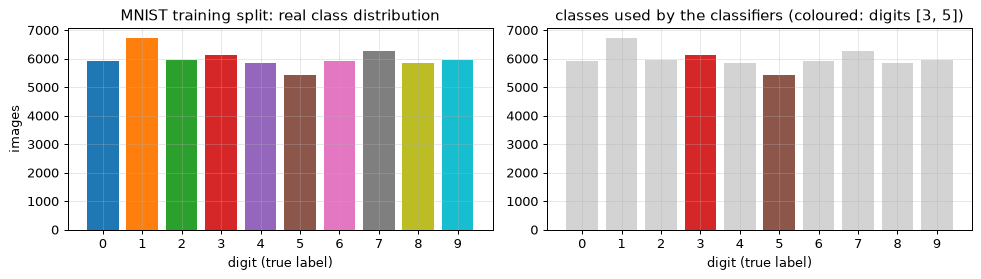

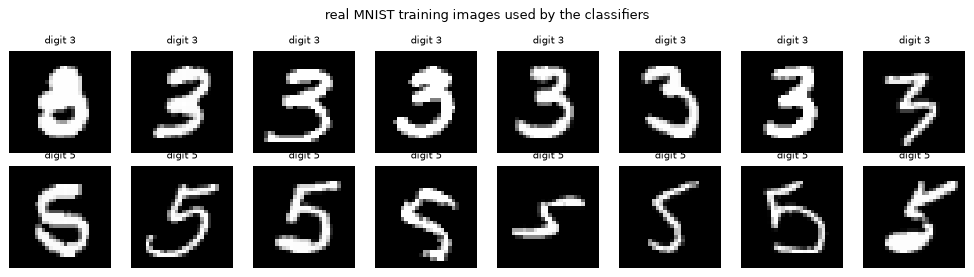

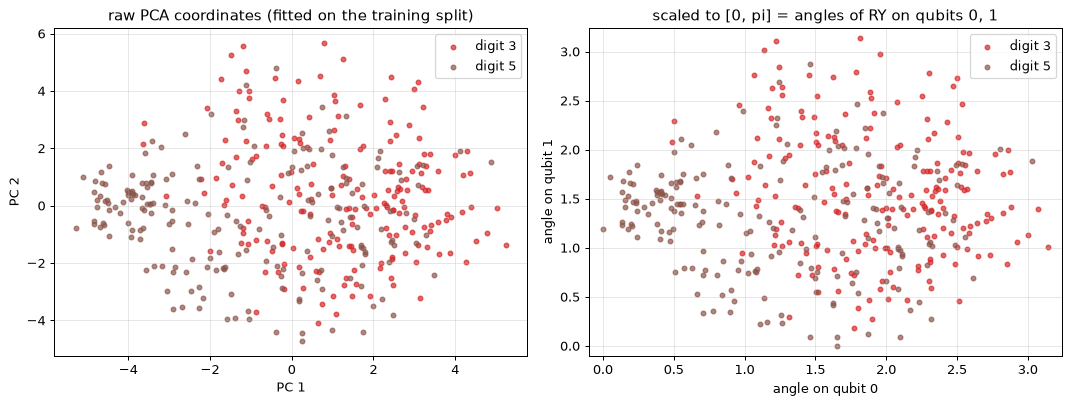

1-qubit task: one angle per image; mean angle digit 3 = 1.94 , digit 5 = 1.22


In [10]:
# ---- 1. MNIST: shape, features, labels, class counts ----
print("MNIST training images:", Xtr_all.shape, "(60000 images of 28 x 28 pixels); test images:", Xte_all.shape)
print("features: 784 pixel intensities pixel_0 ... pixel_783 (uint8, 0..255);  original labels: digits 0..9")
counts_tr = pd.Series(np.bincount(ytr_all), name="train"); counts_te = pd.Series(np.bincount(yte_all), name="test")
print(pd.concat([counts_tr, counts_te], axis=1).T.to_string())
print(f"subset used by every classifier: digits {DIGITS} (labels 0 and 1) | sampled per run:", f"{N_TRAIN} training / {N_TEST} test images, balanced")

cols = plt.cm.tab10(np.arange(10))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(range(10), counts_tr.values, color=cols); axes[0].set_xticks(range(10)); axes[0].set_xlabel("digit (true label)"); axes[0].set_ylabel("images")
axes[0].set_title("MNIST training split: real class distribution")
axes[1].bar(range(10), np.where(np.isin(np.arange(10), DIGITS), counts_tr.values, 0), color=[cols[d] for d in range(10)])
axes[1].bar(range(10), np.where(~np.isin(np.arange(10), DIGITS), counts_tr.values, 0), color="lightgrey")
axes[1].set_xticks(range(10)); axes[1].set_xlabel("digit (true label)"); axes[1].set_title(f"classes used by the classifiers (coloured: digits {DIGITS})")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(11, 3.1)); r = np.random.default_rng(SEED)
for ci, c in enumerate(DIGITS):
    ids = r.choice(np.where(ytr_all == c)[0], 8, replace=False)
    for j, i in enumerate(ids):
        ax = axes[ci, j]; ax.imshow(Xtr_all[i], cmap="gray"); ax.set_title(f"digit {c}", fontsize=8); ax.axis("off")
plt.suptitle("real MNIST training images used by the classifiers", fontsize=10); plt.tight_layout(); plt.show()

# ---- 2-D scatter of the real training images, coloured by the true digit (PCA fitted on the training split), raw coordinates then angles in [0, pi] ----
v = VICT[("8Q;1-layer", SEEDS[0])]; D = v["D"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ci, c in enumerate(DIGITS):
    m = D["ytr"] == ci
    axes[0].scatter(D["raw_tr"][m, 0], D["raw_tr"][m, 1], s=14, alpha=0.7, color=cols[c], label=f"digit {c}")
    axes[1].scatter(D["Xtr"][m, 0], D["Xtr"][m, 1], s=14, alpha=0.7, color=cols[c], label=f"digit {c}")
axes[0].set_title("raw PCA coordinates (fitted on the training split)"); axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2"); axes[0].legend()
axes[1].set_title("scaled to [0, pi] = angles of RY on qubits 0, 1"); axes[1].set_xlabel("angle on qubit 0"); axes[1].set_ylabel("angle on qubit 1")
axes[1].set_xlim(-0.1, np.pi + 0.1); axes[1].set_ylim(-0.1, np.pi + 0.1); axes[1].legend()
plt.tight_layout(); plt.show()
v1 = VICT[("1Q;4-gate", SEEDS[0])]["D"]
print(f"1-qubit task: one angle per image; mean angle digit {DIGITS[0]} =", round(v1["Xtr"][v1["ytr"] == 0, 0].mean(), 2), f", digit {DIGITS[1]} =", round(v1["Xtr"][v1["ytr"] == 1, 0].mean(), 2))

## Quantum Circuit Architecture

Every gate-based model of the paper is drawn here from the objects that are actually executed.

* **The ten classifiers of Table 1** (PennyLane, the paper's framework): `qml.draw_mpl` of the QNode that is trained and evaluated, one drawing per distinct architecture. Each drawing shows the `RY` angle encoding (state preparation, removed
  by the adversary), the trainable rotation blocks, the `CX` chain and the read-out. Qubit count, depth and trainable-parameter count are printed.
* **The countermeasure variants** of Sec. VI (extra layer, dummy qubit, both) on the 2-qubit 3-layer classifier, same way, with the number of fixed (non-trainable) rotations.
* **What the vendor receives** (Qiskit): the transpiled trained part for two architectures, drawn with `circuit.draw("mpl")`. The *reverse-engineered* circuits are drawn in section 4, next to the originals (Figs. 6-7).
* **Equivalence assertions**: the PennyLane trained part has the same unitary as the Qiskit circuit that is transpiled (up to a global phase), and the transpiled circuit has the same unitary as the original, for all circuits.

Assumptions where the paper omits circuit details (encoding, entangler, read-out, 1-qubit and 4/8-qubit layers) are in the choice table at the top.

architecture  qubits  depth  gates  trainable_params  paper_params  cx
   1Q;4-gate       1      5      5                 4             4   0
  2Q;1-layer       2      5      9                 6             6   1
  2Q;2-layer       2      9     16                12            12   2
  2Q;3-layer       2     13     23                18            18   3
  4Q;1-layer       4      6     15                 8             8   3
  4Q;2-layer       4     10     26                16            16   6
  4Q;3-layer       4     14     37                24            24   9
  8Q;1-layer       8     10     31                16            16   7
  8Q;2-layer       8     14     54                32            32  14
  8Q;3-layer       8     18     77                48            48  21
(depth and gate count include the RY encoding layer; the cx column counts the CNOTs of the trained part)


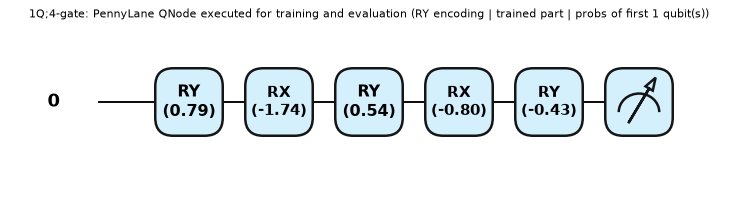

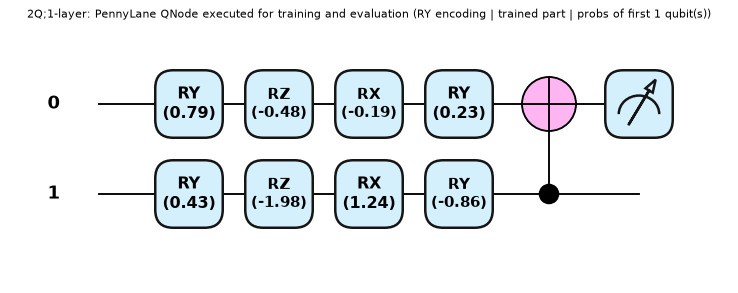

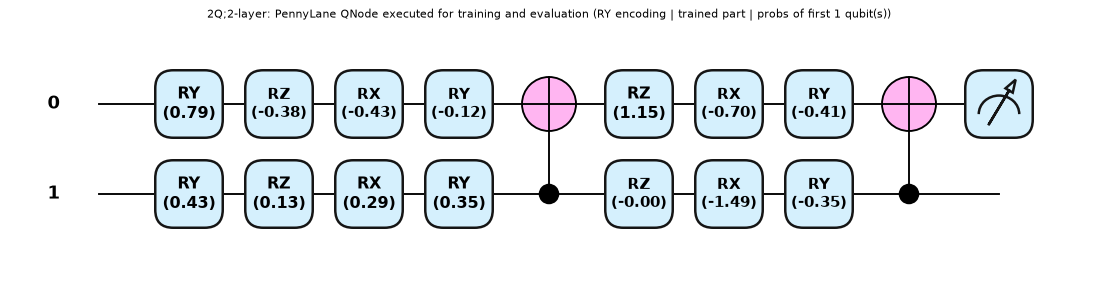

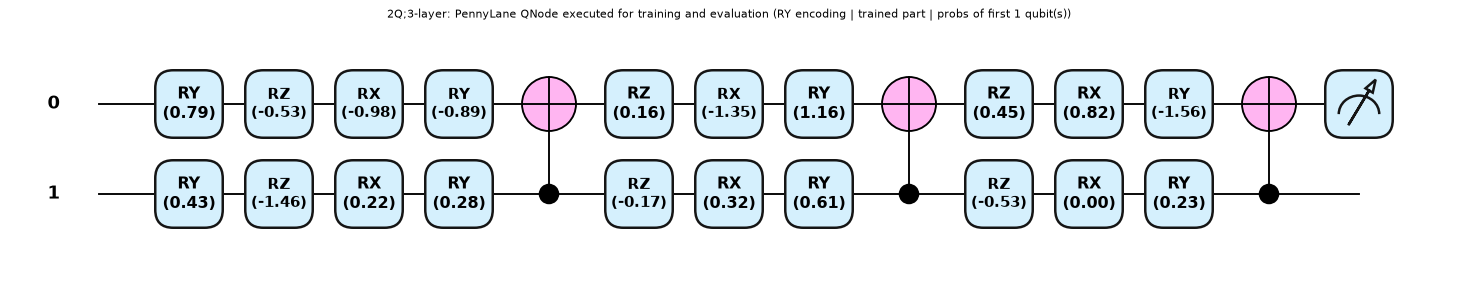

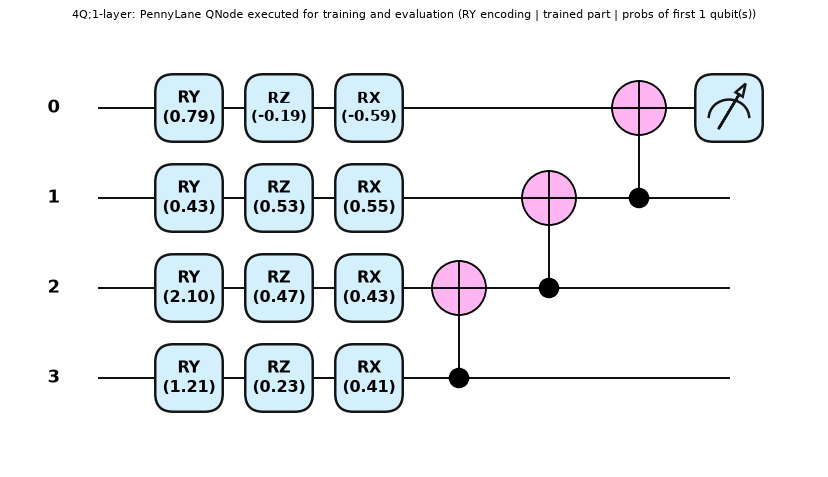

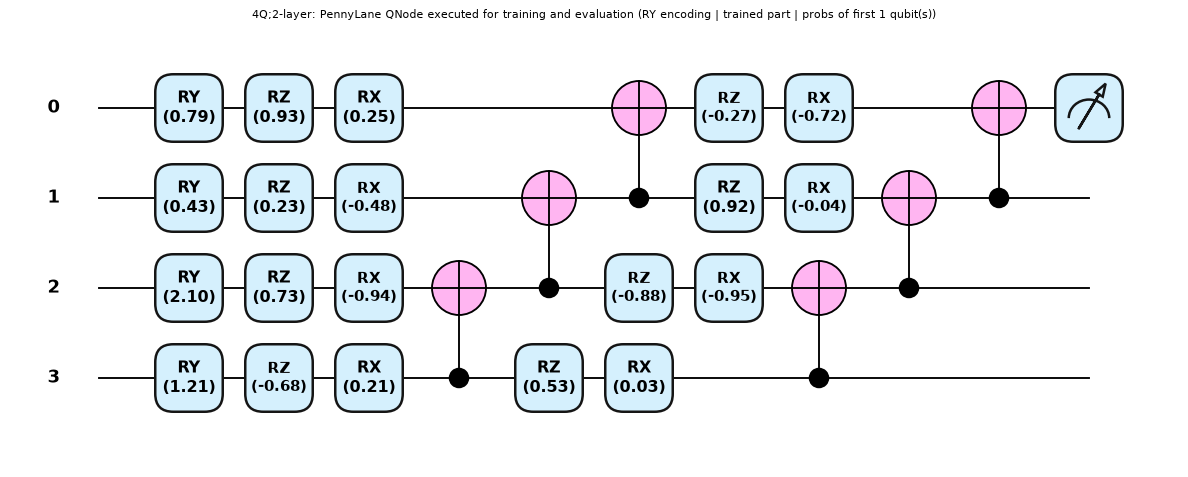

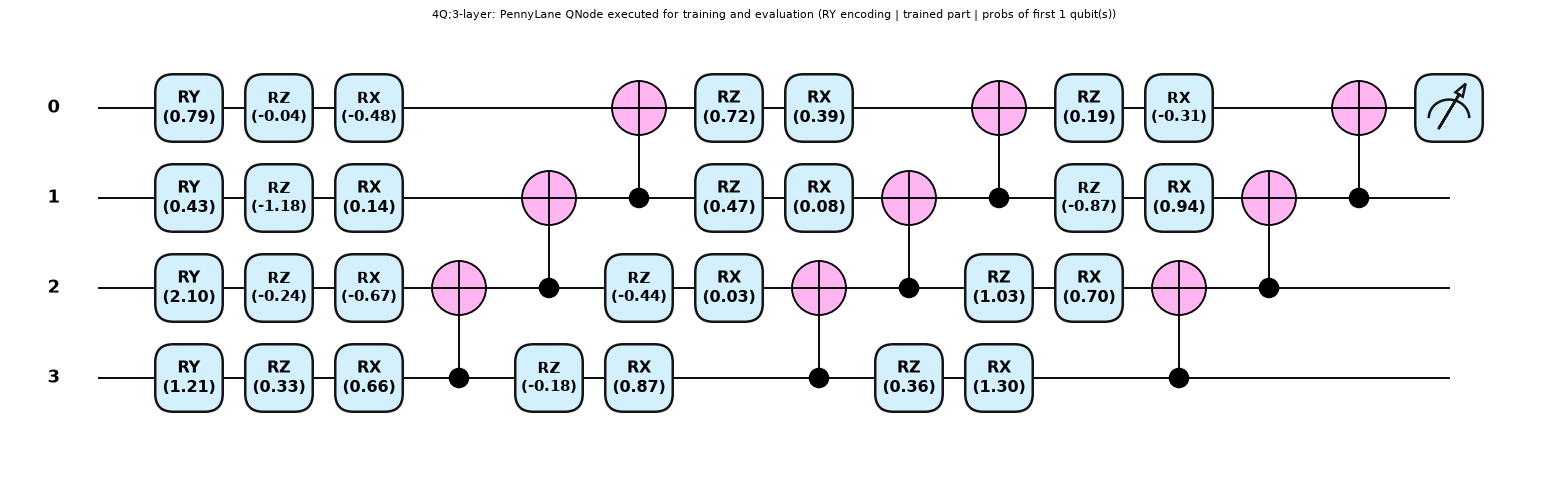

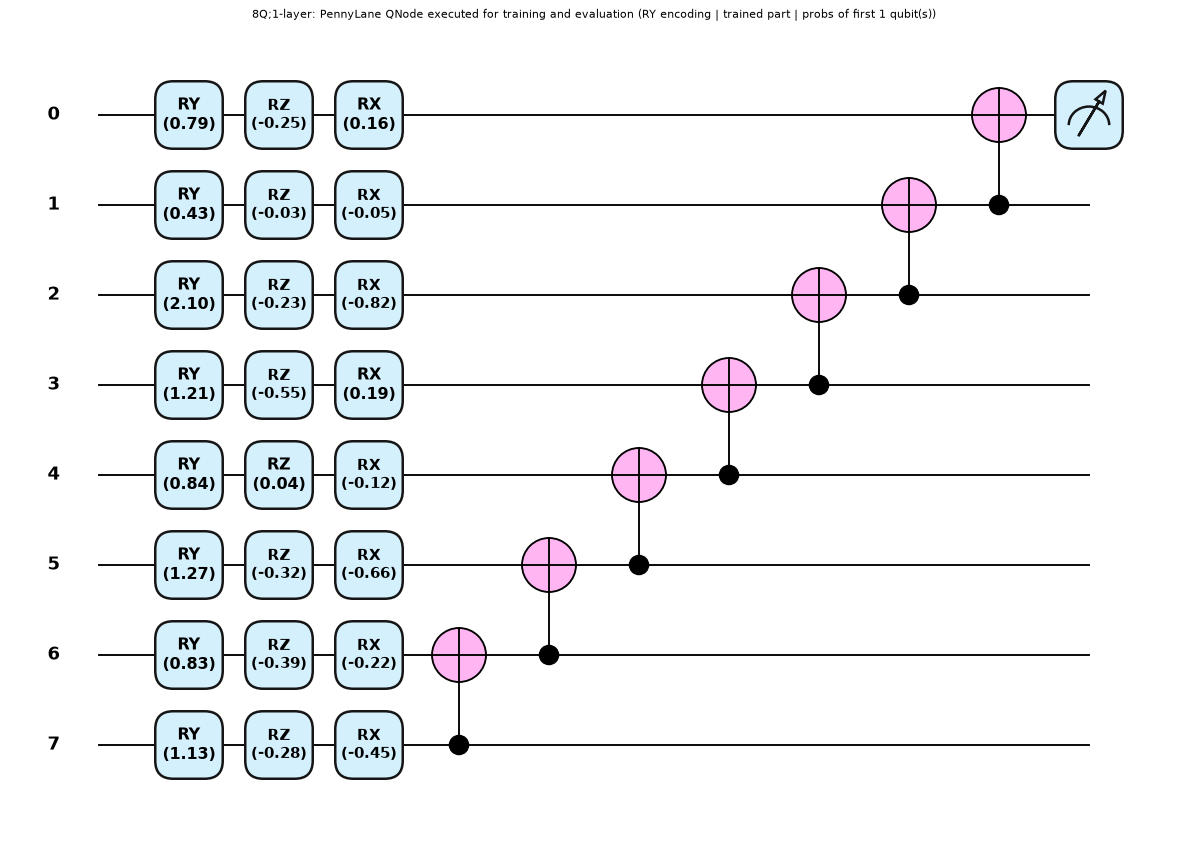

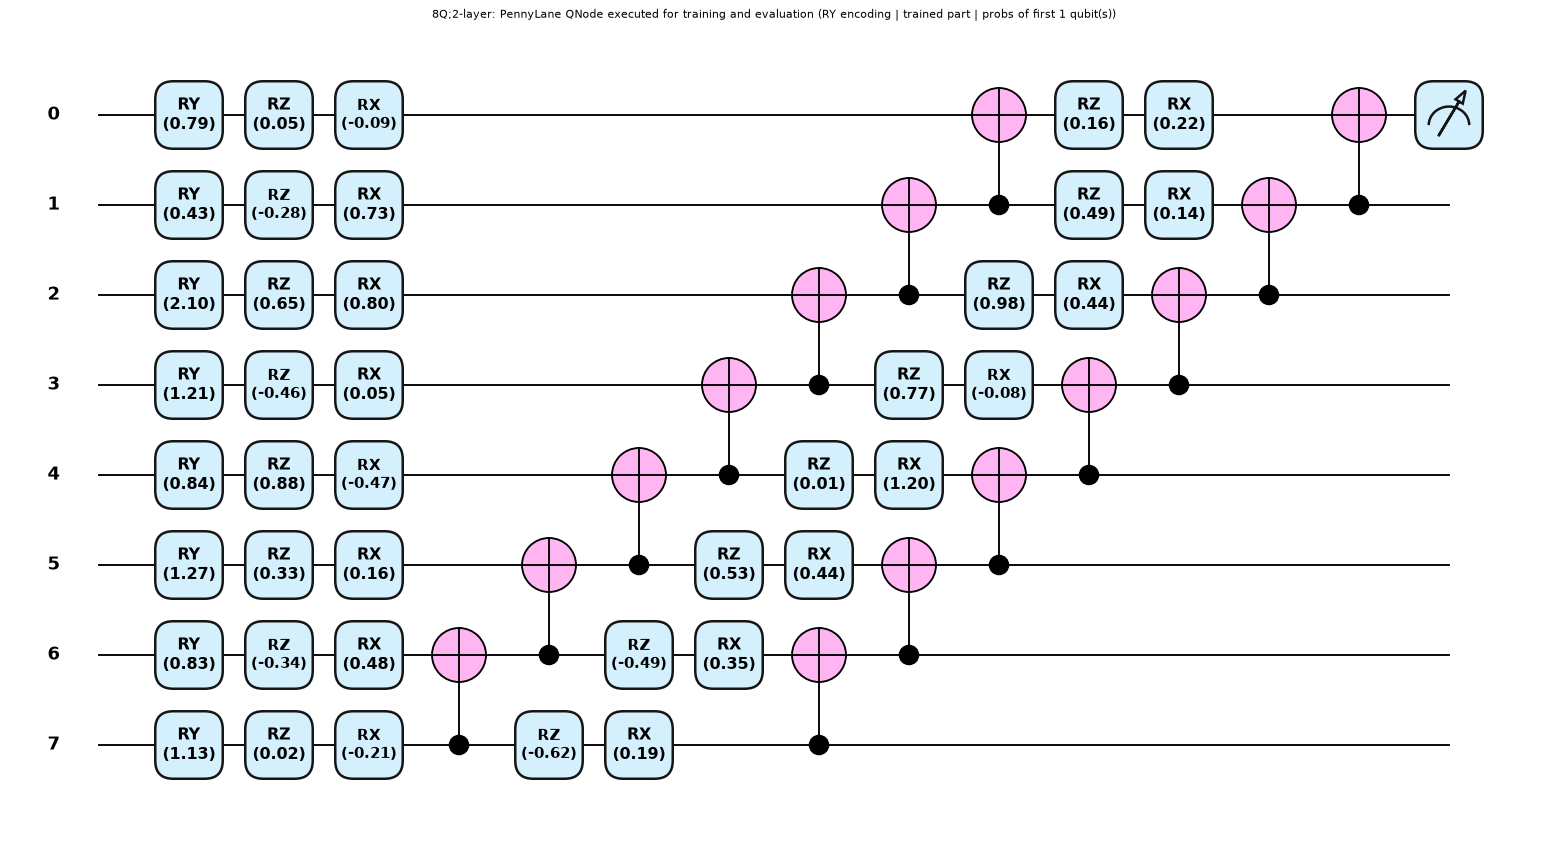

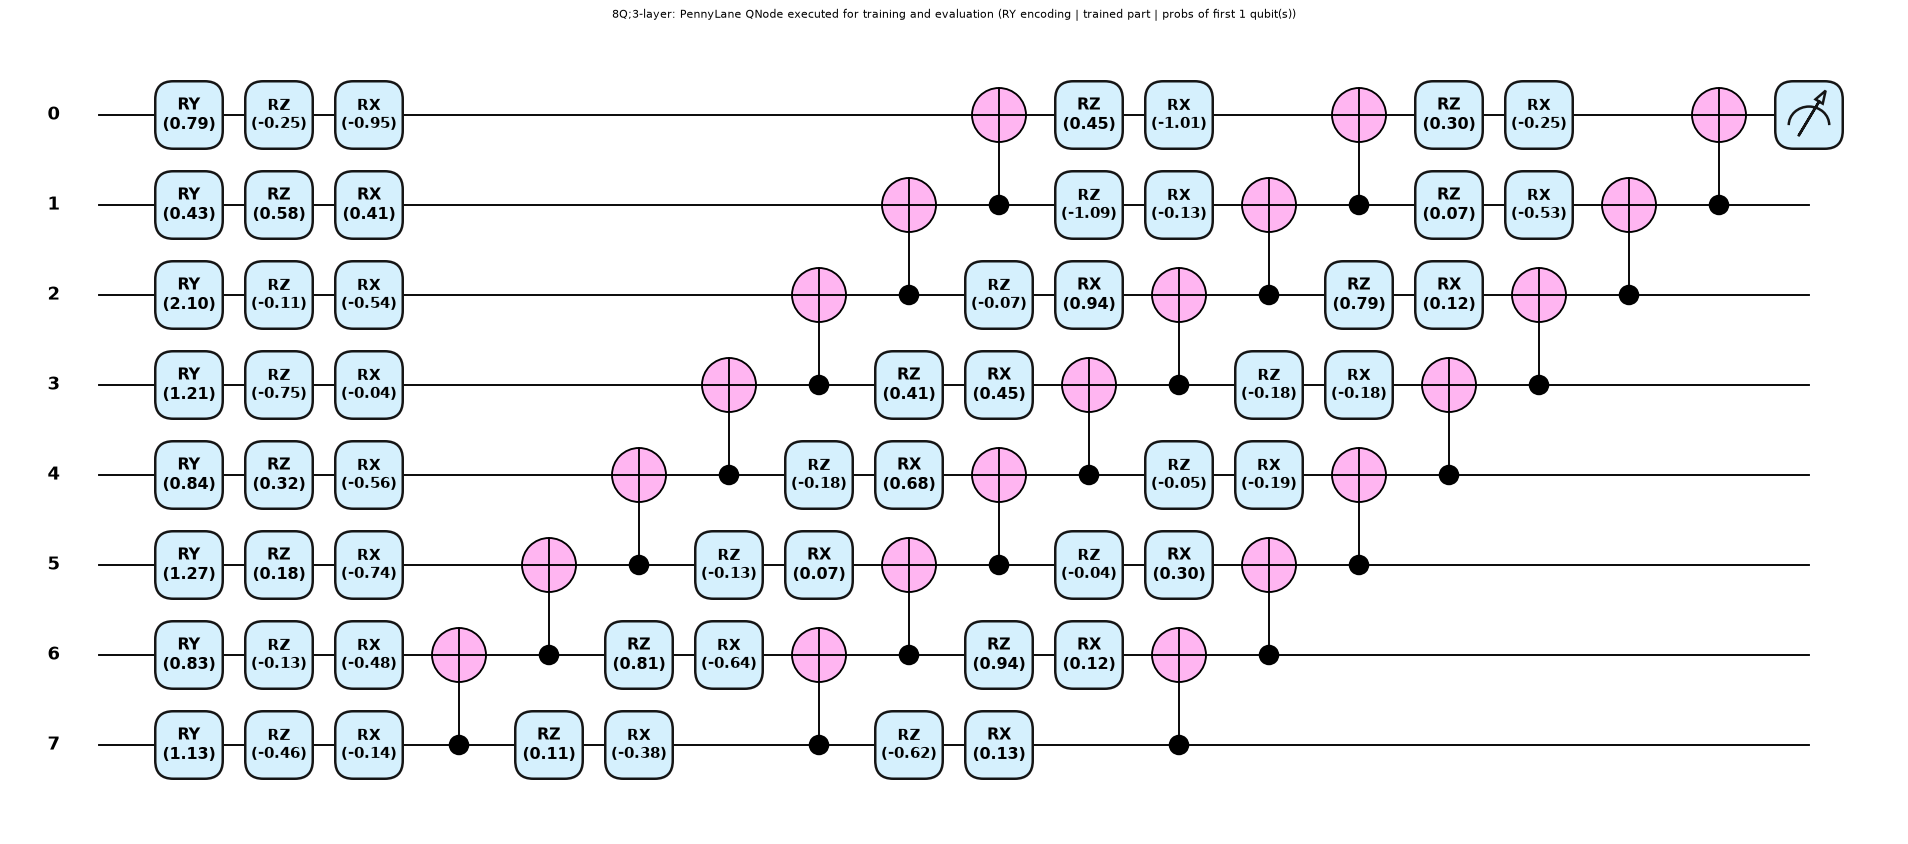

In [11]:
# ---- circuit properties + PennyLane drawings (one per architecture, trained parameters of the first seed) ----
prop = []
for name, n, L, seq in ARCHS:
    v = VICT[(name, SEEDS[0])]
    x0 = pnp.array(v["D"]["Xte"][0], requires_grad=False)
    spec = qml.specs(v["circuit"])(pnp.array(v["theta"]), x0)["resources"]
    prop.append(dict(architecture=name, qubits=v["N"], depth=spec.depth, gates=spec.num_gates, trainable_params=len(v["theta"]), paper_params=PAPER_NPARAMS[name],
                     cx=sum(1 for g in v["gl"] if g[0] == "cx")))
print(pd.DataFrame(prop).to_string(index=False))
print("(depth and gate count include the RY encoding layer; the cx column counts the CNOTs of the trained part)")

for name, n, L, seq in ARCHS:
    v = VICT[(name, SEEDS[0])]
    fig, ax = qml.draw_mpl(v["circuit"], decimals=2, style="pennylane")(pnp.array(v["theta"]), pnp.array(v["D"]["Xte"][0], requires_grad=False))
    fig.suptitle(f"{name}: PennyLane QNode executed for training and evaluation (RY encoding | trained part | probs of first {v['n_out']} qubit(s))", fontsize=9, y=1.02)
    plt.show()

countermeasure victims trained in 109 s


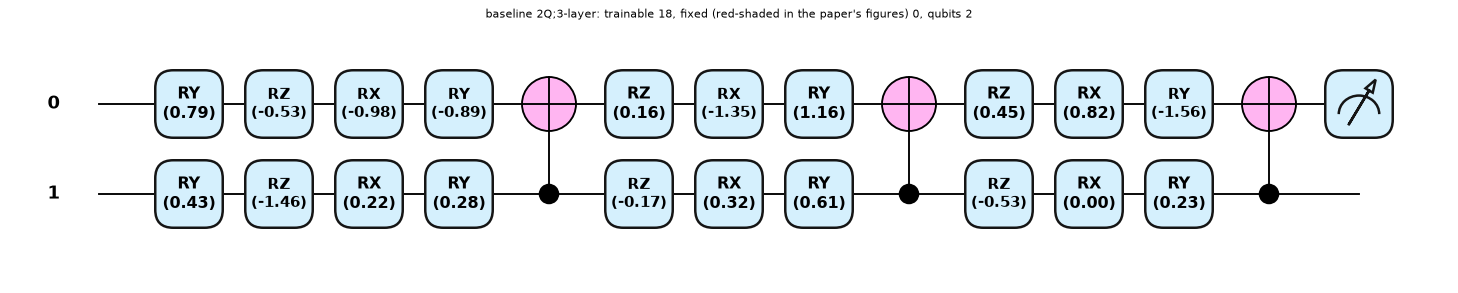

baseline 2Q;3-layer                      qubits 2  trainable 18  fixed  0  CX 3


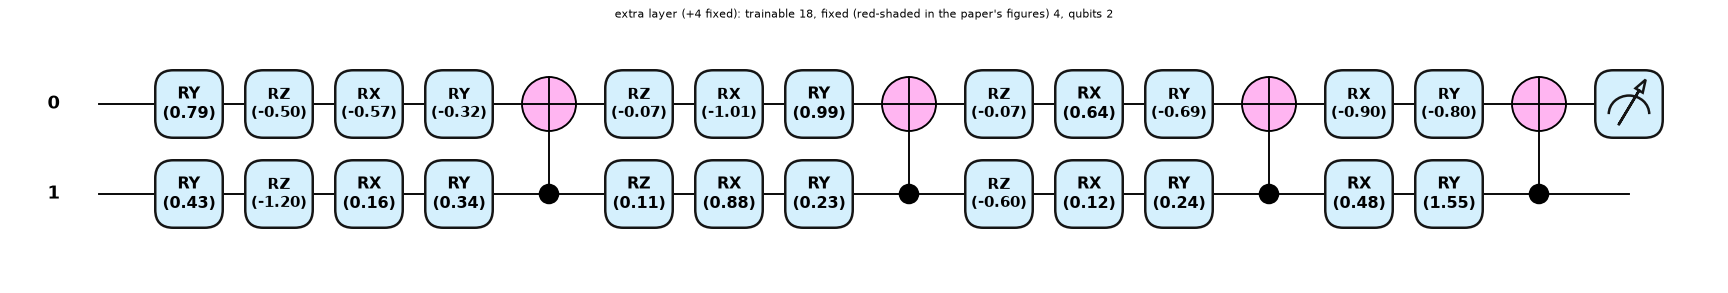

extra layer (+4 fixed)                   qubits 2  trainable 18  fixed  4  CX 4


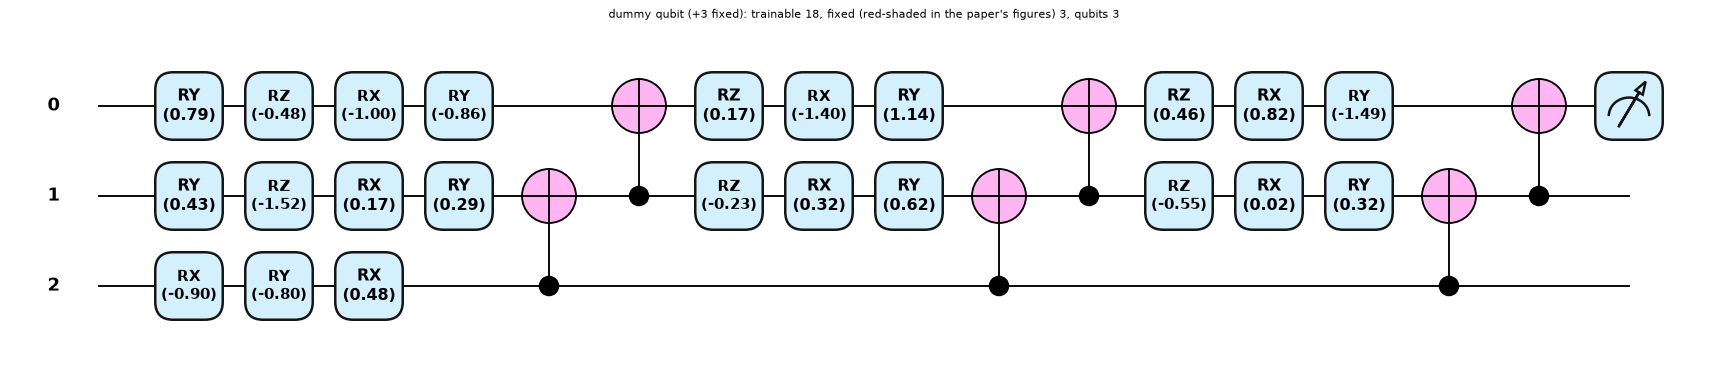

dummy qubit (+3 fixed)                   qubits 3  trainable 18  fixed  3  CX 6


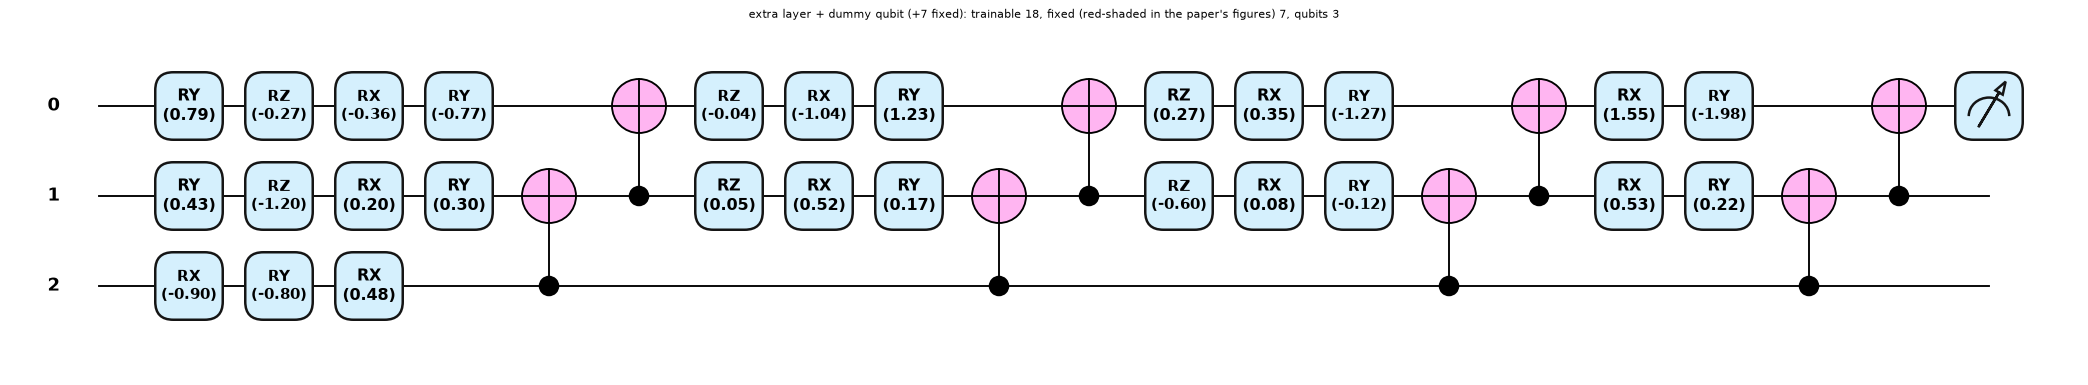

extra layer + dummy qubit (+7 fixed)     qubits 3  trainable 18  fixed  7  CX 8


In [12]:
# ---- the countermeasure variants of Sec. VI on the 2-qubit 3-layer baseline (trained below; drawn here) ----
CM_SPECS = {"baseline 2Q;3-layer": (0, 0), "extra layer (+4 fixed)": (1, 0), "dummy qubit (+3 fixed)": (0, 1), "extra layer + dummy qubit (+7 fixed)": (1, 1)}
CMV = {}
t0 = time.time()
for seed in SEEDS:
    for key, (dl, dq) in CM_SPECS.items():
        CMV[(key, seed)] = make_victim("2Q;3-layer", 2, 3, "zxy", seed, dummy_layers=dl, dummy_qubits=dq, tag=key)
        v = CMV[(key, seed)]
        d_sim = np.abs(np.asarray(v["circuit"](pnp.array(v["theta"]), pnp.array(v["D"]["Xte"][:20], requires_grad=False)))
                       - v["sim"].probs(torch.tensor(v["theta"]), torch.tensor(v["D"]["Xte"][:20]), v["n_out"]).numpy()).max()
        assert d_sim < 1e-10, "fast simulator differs from the PennyLane circuit"
print(f"countermeasure victims trained in {time.time()-t0:.0f} s")
for key in CM_SPECS:
    v = CMV[(key, SEEDS[0])]
    fig, ax = qml.draw_mpl(v["circuit"], decimals=2, style="pennylane")(pnp.array(v["theta"]), pnp.array(v["D"]["Xte"][0], requires_grad=False))
    fig.suptitle(f"{key}: trainable {n_trainable(v['gl'])}, fixed (red-shaded in the paper's figures) {n_fixed(v['gl'])}, qubits {v['N']}", fontsize=9, y=1.02); plt.show()
    print(f"{key:40s} qubits {v['N']}  trainable {n_trainable(v['gl']):2d}  fixed {n_fixed(v['gl']):2d}  CX {sum(1 for g in v['gl'] if g[0]=='cx')}")

2Q;1-layer: transpiled circuit  qubits 2  depth 6  size 11  ops {'rz': 6, 'sx': 4, 'cx': 1}  (linear coupling map, basis ['id', 'x', 'sx', 'cx', 'rz'], level 1)


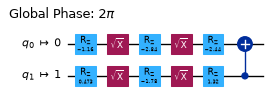

4Q;1-layer: transpiled circuit  qubits 4  depth 8  size 23  ops {'rz': 12, 'sx': 8, 'cx': 3}  (linear coupling map, basis ['id', 'x', 'sx', 'cx', 'rz'], level 1)


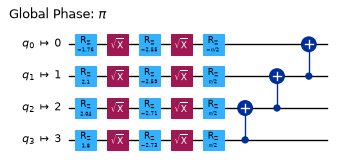

In [13]:
# ---- what the vendor receives: transpiled trained part (Qiskit), two architectures ----
for name in ["2Q;1-layer", "4Q;1-layer"]:
    v = VICT[(name, SEEDS[0])]
    tc = vendor_transpile(qiskit_trained(v["theta"], v["gl"], v["N"])); v["tc"] = tc
    print(f"{name}: transpiled circuit  qubits {tc.num_qubits}  depth {tc.depth()}  size {tc.size()}  ops {dict(tc.count_ops())}  (linear coupling map, basis {BASIS_GATES}, level {OPT_LEVEL})")
    display(tc.draw("mpl", fold=40, scale=0.55))

In [14]:
# ---- equivalence assertions: PennyLane circuit == Qiskit twin == transpiled circuit == FastSim ----
eq = []
for (name, seed), v in VICT.items():
    if seed != SEEDS[0]: continue
    U_pl = pl_unitary(v["theta"], v["gl"], v["N"])                              # PennyLane: wire 0 = most significant qubit
    qc = qiskit_trained(v["theta"], v["gl"], v["N"]); tc = vendor_transpile(qc); v["tc"] = tc
    U_q = Operator(qc.reverse_bits()).data; U_tr = Operator(tc.reverse_bits()).data   # Qiskit is little endian -> reverse
    o1, o2 = abs(np.trace(U_pl.conj().T @ U_q)) / U_pl.shape[0], abs(np.trace(U_q.conj().T @ U_tr)) / U_q.shape[0]
    assert o1 > 1 - 1e-9, f"{name}: PennyLane and Qiskit circuits differ ({o1})"
    assert o2 > 1 - 1e-9, f"{name}: transpiled circuit differs from the original ({o2})"
    eq.append(dict(architecture=name, pennylane_vs_qiskit=o1, original_vs_transpiled=o2))
for (key, seed), v in CMV.items():
    if seed != SEEDS[0]: continue
    U_pl = pl_unitary(v["theta"], v["gl"], v["N"]); qc = qiskit_trained(v["theta"], v["gl"], v["N"]); tc = vendor_transpile(qc); v["tc"] = tc
    o1 = abs(np.trace(U_pl.conj().T @ Operator(qc.reverse_bits()).data)) / U_pl.shape[0]; o2 = abs(np.trace(Operator(qc).data.conj().T @ Operator(tc).data)) / U_pl.shape[0]
    assert o1 > 1 - 1e-9 and o2 > 1 - 1e-9, key
    eq.append(dict(architecture=key, pennylane_vs_qiskit=o1, original_vs_transpiled=o2))
print(pd.DataFrame(eq).to_string(index=False, float_format=lambda x: f"{x:.12g}"))
print("All circuits: |tr(U_A^dagger U_B)| / 2^n = 1 (equal up to a global phase): the drawn PennyLane circuit, its Qiskit twin and the transpiled circuit implement the same unitary;",
      "the FastSim used for the gradient loops reproduces the PennyLane probabilities (asserted for every trained victim above).")

                        architecture  pennylane_vs_qiskit  original_vs_transpiled
                           1Q;4-gate                    1                       1
                          2Q;1-layer                    1                       1
                          2Q;2-layer                    1                       1
                          2Q;3-layer                    1                       1
                          4Q;1-layer                    1                       1
                          4Q;2-layer                    1                       1
                          4Q;3-layer                    1                       1
                          8Q;1-layer                    1                       1
                          8Q;2-layer                    1                       1
                          8Q;3-layer                    1                       1
                 baseline 2Q;3-layer                    1                       1
              ex

## 3. The attack: Algorithm 1 (parser, LUT, exhaustive search)

1. **Parse** the transpiled circuit: for every qubit, the run of single-qubit gates between two `CX` gates is a *block*; the `CX` gates give the entanglement.
2. **LUT**: from the three `RZ` angles of the block, decide the template (here two entries, see the choice table).
3. **Search** (`reverse`): enumerate every parameter combination of the template on the grid `[-pi, pi)` with step `N`, compute what the transpiler would make of it, and keep the combination whose transpiled angles are closest.
4. **Rebuild** the pre-transpilation model: same `CX` gates, one template per block with the recovered angles. Because merged blocks are reported as one template, the reverse-engineered model has the same function
   but may have fewer parameters than the user's.

Time complexity of the search: one candidate per grid point, i.e. `(2 pi / N)^k` candidates for `k` angles per block. The first cell below checks that the vectorised search used for speed returns the same answer as the literal search.

In [15]:
def parse_blocks(tc):
    """Algorithm 1, `parser`: split a transpiled circuit qubit by qubit into runs of single-qubit gates between two CX gates.
    Returns the ordered event list [('block', qubit, [instructions]) | ('cx', control, target)] in circuit order."""
    n = tc.num_qubits; pend = [[] for _ in range(n)]; events = []
    for inst in tc.data:
        qs = [tc.find_bit(q).index for q in inst.qubits]; nm = inst.operation.name
        if nm == "cx":
            for q in qs:
                if pend[q]: events.append(("block", q, pend[q])); pend[q] = []
            events.append(("cx", qs[0], qs[1]))
        elif nm != "barrier":
            pend[qs[0]].append(inst)
    for q in range(n):
        if pend[q]: events.append(("block", q, pend[q]))
    return events

def seg_to_qc(seg):
    qc = QuantumCircuit(1)
    for i in seg: getattr(qc, i.operation.name)(*[float(p) for p in i.operation.params], 0)
    return qc

def lut_template(phis, tol=1e-6):
    """Look-up table of Fig. 5 (cases 1 and 4): which original rotation template produces the transpiled pattern RZ(p0) SX RZ(p1) SX RZ(p2)?
    |p2| = pi/2  -> RZ then RX (this includes a lone RX and stacked RXs): template 'zx', 2 parameters;
    otherwise   -> a general product of rotations: template 'xyz' (RX(phi1) RY(phi2) RZ(phi3)), 3 parameters."""
    return "zx" if abs(abs(wrap(phis[2])) - np.pi / 2) < tol else "xyz"

LUT_TEMPLATES = ["zx", "xyz"]

In [16]:
def grid_axes(step):
    return np.arange(-np.pi, np.pi, step)

def n_candidates(template, step):
    return len(grid_axes(step)) ** len(template)

def exhaustive_search(phis, template, step, chunk=CHUNK):
    """Algorithm 1, `reverse`: try EVERY parameter combination of the LUT template on the grid [-pi, pi) with the given step, compute the angles the transpiler would give for it
    (vectorised copy of the Euler decomposition, asserted equal to qiskit.transpile in section 1) and keep the candidate whose transpiled angles are closest (sum of absolute angle differences).
    Returns (estimated original parameters, remaining transpiled-angle distance)."""
    g = grid_axes(step); k = len(template); tot = len(g) ** k
    best_d, best_th = np.inf, None
    for s in range(0, tot, chunk):
        idx = np.arange(s, min(s + chunk, tot))
        th = np.stack([g[(idx // len(g) ** (k - 1 - j)) % len(g)] for j in range(k)], 1)
        P = zsx_params(seq_unitary(template, th))
        d = np.abs(wrap(P - phis[None, :])).sum(1); i = int(np.argmin(d))
        if d[i] < best_d: best_d, best_th = float(d[i]), th[i].copy()
    return best_th, best_d

def literal_search(phis, template, step):
    """The same search, but literally as in Algorithm 1: build the candidate circuit, run it through the vendor's transpiler and compare the RZ angles."""
    g = grid_axes(step); best_d, best_th = np.inf, None
    for th in itertools.product(g, repeat=len(template)):
        P = block_phis(vendor_transpile(template_circuit(template, th)))
        d = float(np.abs(wrap(P - phis)).sum())
        if d < best_d: best_d, best_th = d, np.array(th)
    return best_th, best_d

def reverse_engineer(tc, step=BRUTE_STEP, search=exhaustive_search):
    """Reverse engineer a transpiled trained circuit: parse it, recognise the template of every block with the LUT, search the block's angles, and rebuild a gate list
    (the pre-transpilation model of the adversary). Returns (gate list with parameter indices, parameter vector, per-block records, seconds spent in the search)."""
    events = parse_blocks(tc); gl, params, recs = [], [], []; t_search = 0.0
    for ev in events:
        if ev[0] == "cx":
            gl.append(("cx", ev[1], ev[2], None)); continue
        q, seg = ev[1], ev[2]
        phis = block_phis(seg_to_qc(seg)); tmpl = lut_template(phis)
        t0 = time.time(); th, dist = search(phis, tmpl, step); t_search += time.time() - t0
        for gname, val in zip(tmpl, th):
            gl.append((gname, q, len(params), None)); params.append(float(val))
        recs.append(dict(qubit=q, template=tmpl, phis=phis, theta=th, dist=dist))
    return gl, np.array(params), recs, t_search

def sim_accuracy(gl, params, N, n_data, D, C, n_out, which="Xte"):
    sim = FastSim(N, n_data, gl)
    return accuracy_sim(sim, params, D[which], D["yte" if which == "Xte" else "ytr"], C, n_out)

def transpiled_angle_error(tc_a, tc_b):
    """Paper Sec. V-C: difference between the parameters (RZ angles) of the original transpiled circuit and of the transpiled reverse-engineered circuit.
    Returns the list of per-parameter absolute differences (circular), matched block by block."""
    ea = [e for e in parse_blocks(tc_a) if e[0] == "block"]; eb = [e for e in parse_blocks(tc_b) if e[0] == "block"]
    assert len(ea) == len(eb), "block structure differs"
    out = []
    for a, b in zip(ea, eb):
        out += list(np.abs(wrap(block_phis(seg_to_qc(a[2])) - block_phis(seg_to_qc(b[2])))))
    return np.array(out)

In [17]:
# ---- validation of the search: the vectorised exhaustive search returns the same candidate as the literal one (re-transpile every candidate) ----
T_TR = {}
for tm in LUT_TEMPLATES:
    r = np.random.default_rng(SEED + 11); t0 = time.time()
    for _ in range(N_TIMING):
        vendor_transpile(template_circuit(tm, r.uniform(-np.pi, np.pi, len(tm))))
    T_TR[tm] = (time.time() - t0) / N_TIMING
print({k: f"{x*1000:.1f} ms per qiskit.transpile call (one-block circuit)" for k, x in T_TR.items()})

v = VICT[("2Q;1-layer", SEEDS[0])]; tcv = v["tc"]
blk = [e for e in parse_blocks(tcv) if e[0] == "block"][0]; phis = block_phis(seg_to_qc(blk[2])); tm = lut_template(phis)
t0 = time.time(); th_v, d_v = exhaustive_search(phis, tm, LITERAL_STEP); t_v = time.time() - t0
t0 = time.time(); th_l, d_l = literal_search(phis, tm, LITERAL_STEP); t_l = time.time() - t0
print(f"block of 2Q;1-layer, template {tm}, step {LITERAL_STEP}: {n_candidates(tm, LITERAL_STEP)} candidates")
print(f"  vectorised search: {t_v:.3f} s -> {np.round(th_v, 3)}, angle distance {d_v:.4f}")
print(f"  literal (transpile each candidate): {t_l:.1f} s -> {np.round(th_l, 3)}, angle distance {d_l:.4f}")
assert np.allclose(th_v, th_l) and abs(d_v - d_l) < 1e-8, "vectorised and literal search disagree"
print(f"identical answer; the literal search is {t_l/max(t_v,1e-9):.0f}x slower, i.e. {t_l/n_candidates(tm, LITERAL_STEP)*1000:.1f} ms per candidate (the paper's brute force is of this kind, Table 2).")

{'zx': '13.6 ms per qiskit.transpile call (one-block circuit)', 'xyz': '10.6 ms per qiskit.transpile call (one-block circuit)'}


block of 2Q;1-layer, template xyz, step 0.4: 4096 candidates
  vectorised search: 0.010 s -> [-1.942  2.058  2.458], angle distance 0.1564
  literal (transpile each candidate): 57.3 s -> [-1.942  2.058  2.458], angle distance 0.1564
identical answer; the literal search is 5729x slower, i.e. 14.0 ms per candidate (the paper's brute force is of this kind, Table 2).


### 3b. Reversing the entanglement (Sec. IV-A)

On a coupling map where the circuit's `CX` gates are already neighbours (the paper's linear map), the `CX` list of the transpiled circuit *is* the entanglement structure. When the router has to insert `SWAP` gates (T-shaped map of
Fig. 3), each one appears as the triple `CX(a,b) CX(b,a) CX(a,b)`; the parser undoes it by relabelling the two qubits from then on. The check runs random 4-qubit circuits on the T-shaped map and compares the recovered logical `CX` list
with the true one.

In [18]:
# ---- Sec. IV-A: reversing the entanglement ----
def reverse_entanglement(tc):
    """Read the logical CNOT list out of a transpiled circuit: every triple cx(a,b) cx(b,a) cx(a,b) is a SWAP inserted by the router (undo it by relabelling), every other cx is a logical CNOT."""
    cxs = [(e[1], e[2]) for e in parse_blocks(tc) if e[0] == "cx"]; loc = list(range(tc.num_qubits)); out = []; i = 0   # loc[physical] = logical
    while i < len(cxs):
        if i + 2 < len(cxs) and cxs[i] == cxs[i + 2] and cxs[i + 1] == (cxs[i][1], cxs[i][0]):
            a, b = cxs[i]; loc[a], loc[b] = loc[b], loc[a]; i += 3
        else:
            out.append((loc[cxs[i][0]], loc[cxs[i][1]])); i += 1
    return out

# (a) the classifiers of the paper: linear coupling map, no SWAPs needed -> the CNOT list is read off directly
for name in ["2Q;3-layer", "4Q;2-layer", "8Q;3-layer"]:
    v = VICT[(name, SEEDS[0])]
    tc = vendor_transpile(qiskit_trained(v["theta"], v["gl"], v["N"]))
    orig = [(g[1], g[2]) for g in v["gl"] if g[0] == "cx"]
    assert reverse_entanglement(tc) == orig, name
    print(f"{name}: {len(orig)} logical CNOTs recovered exactly from the transpiled circuit (linear coupling map)")

# (b) a circuit that needs routing: T-shaped coupling map of Fig. 3 (qubit 1 in the centre), non-adjacent CNOTs force SWAPs
T_MAP = CouplingMap([(0, 1), (1, 0), (1, 2), (2, 1), (1, 3), (3, 1)])
for trial in range(5):
    r = np.random.default_rng(trial); qc = QuantumCircuit(4); orig = []
    for _ in range(6):
        a, b = map(int, r.choice(4, 2, replace=False)); qc.rx(float(r.uniform(-3, 3)), a); qc.cx(a, b); orig.append((a, b))
    tc = vendor_transpile(qc, coupling_map=T_MAP)
    rec = reverse_entanglement(tc)
    print(f"T-shaped map, random circuit {trial}: {len(orig)} logical CNOTs, transpiled cx count {tc.count_ops().get('cx', 0)}, recovered list equals original: {rec == orig}")

2Q;3-layer: 3 logical CNOTs recovered exactly from the transpiled circuit (linear coupling map)
4Q;2-layer: 6 logical CNOTs recovered exactly from the transpiled circuit (linear coupling map)
8Q;3-layer: 21 logical CNOTs recovered exactly from the transpiled circuit (linear coupling map)
T-shaped map, random circuit 0: 6 logical CNOTs, transpiled cx count 12, recovered list equals original: False


T-shaped map, random circuit 1: 6 logical CNOTs, transpiled cx count 12, recovered list equals original: True
T-shaped map, random circuit 2: 6 logical CNOTs, transpiled cx count 9, recovered list equals original: True
T-shaped map, random circuit 3: 6 logical CNOTs, transpiled cx count 12, recovered list equals original: True


T-shaped map, random circuit 4: 6 logical CNOTs, transpiled cx count 12, recovered list equals original: False


## 4. Examples 1 and 2 of Sec. V-B (Figs. 6 and 7)

For each example the three circuits are drawn: the user's trained circuit, the transpiled circuit the vendor receives, and the adversary's reverse-engineered circuit. The 1-qubit classifier has four rotations (`RX RY RX RY`) that
transpile into a single block; the reverse engineering reports it as three (`RX RY RZ`). With two qubits, the three rotations of a layer fuse into one block per qubit, and the `CX` gates keep the layers apart, so a
2-layer classifier keeps its two blocks per qubit (the paper observes that the second layer is reversed with a different LUT case, Fig. 7). The text prints the number of parameters before and after, the accuracies and the parameter error.

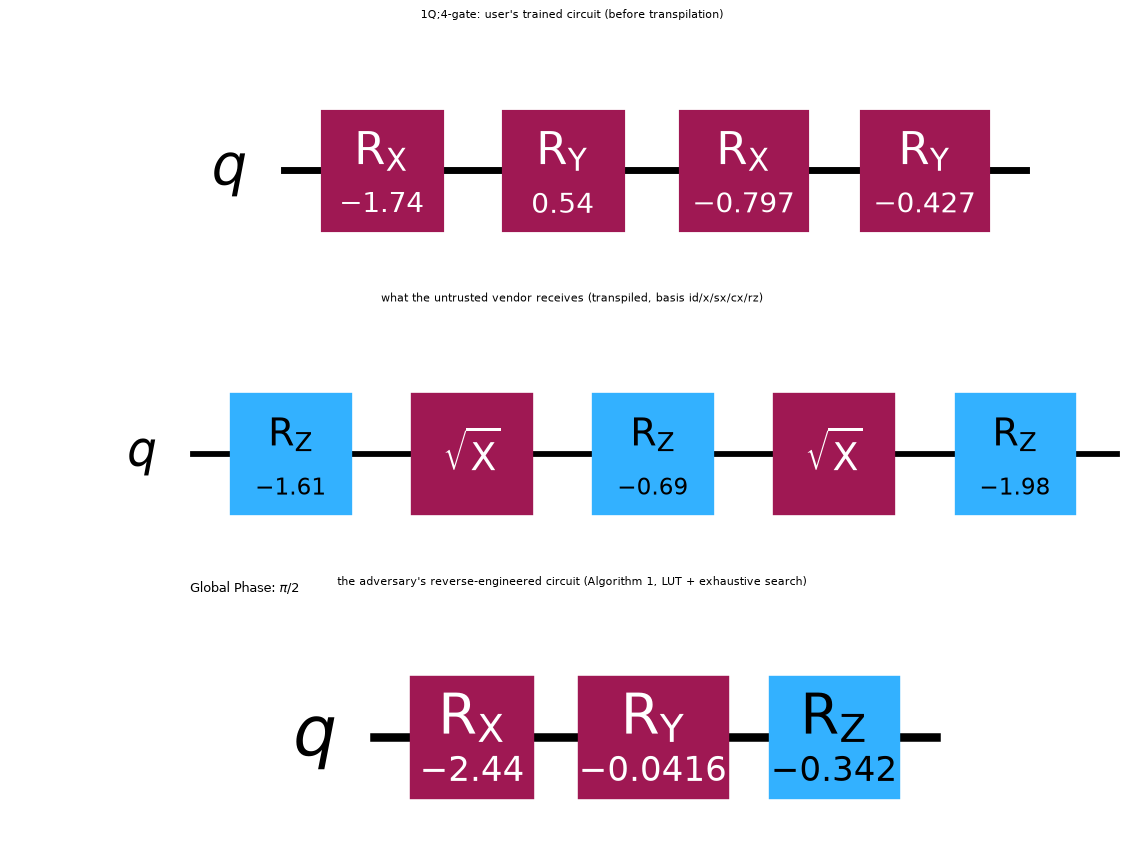

1Q;4-gate: parameters 4 -> 3 after reverse engineering | templates of the blocks: ['xyz']
   training accuracy original 0.6750, reverse-engineered 0.6825 | test accuracy original 0.7025, reverse-engineered 0.7050
   mean error of the transpiled parameters 1.712e-02 (paper Table 1) | distance between the two unitaries 1.977e-02 | search time 1.14 s


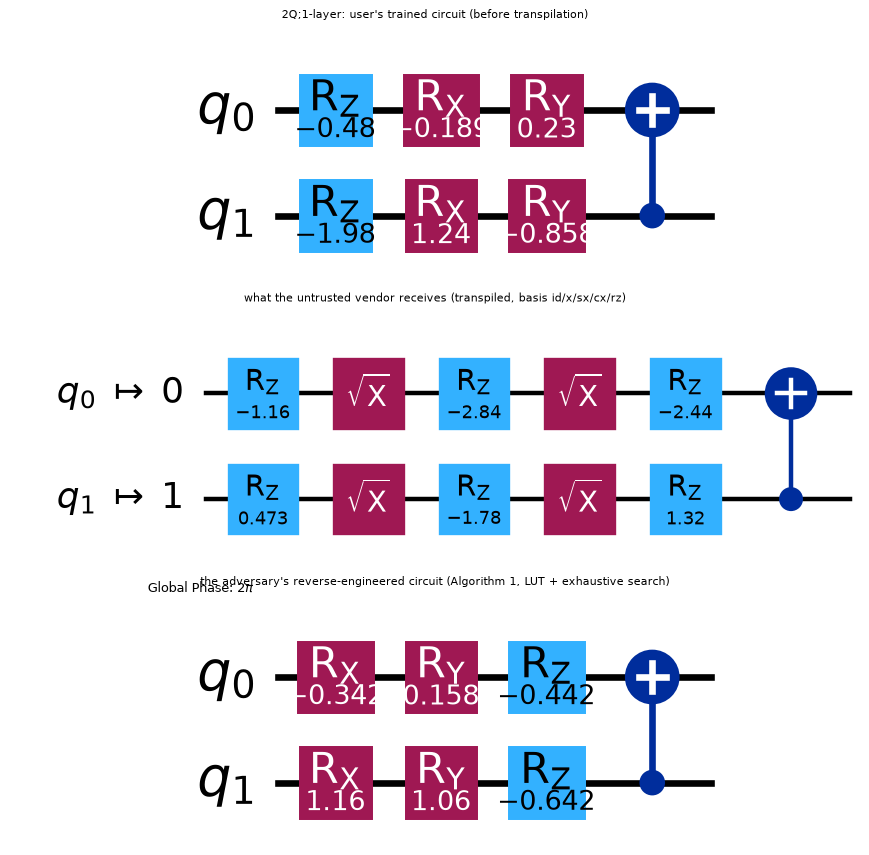

2Q;1-layer: parameters 6 -> 6 after reverse engineering | templates of the blocks: ['xyz', 'xyz']
   training accuracy original 0.6900, reverse-engineered 0.6975 | test accuracy original 0.7025, reverse-engineered 0.7000
   mean error of the transpiled parameters 2.754e-02 (paper Table 1) | distance between the two unitaries 4.726e-02 | search time 2.69 s


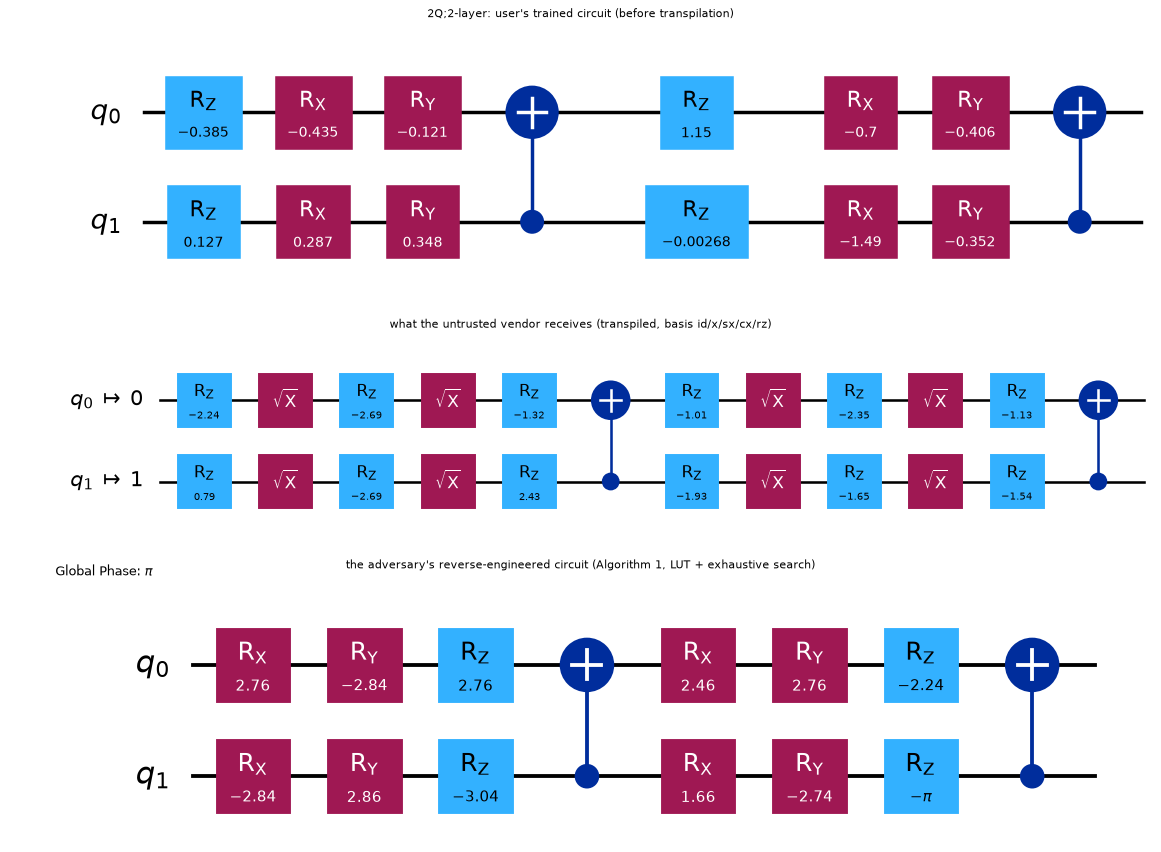

2Q;2-layer: parameters 12 -> 12 after reverse engineering | templates of the blocks: ['xyz', 'xyz', 'xyz', 'xyz']
   training accuracy original 0.7125, reverse-engineered 0.7075 | test accuracy original 0.7100, reverse-engineered 0.7050
   mean error of the transpiled parameters 2.041e-02 (paper Table 1) | distance between the two unitaries 4.756e-02 | search time 6.74 s


In [19]:
# ---- Examples 1 and 2 of Sec. V-B: transpile -> reverse engineer -> compare (Figs. 6 and 7) ----
def accuracy_sim_gl(gl2, p2, v, which="Xte"):
    sim = FastSim(v["N"], v["n"], gl2)
    X, y = (v["D"]["Xte"], v["D"]["yte"]) if which == "Xte" else (v["D"]["Xtr"], v["D"]["ytr"])
    return accuracy_sim(sim, p2, X, y, v["C"], v["n_out"])

def run_re(v, step=BRUTE_STEP):
    """Full attack on one victim: transpile, reverse engineer, re-transpile the stolen model, and compare with the original."""
    tc = vendor_transpile(qiskit_trained(v["theta"], v["gl"], v["N"]))
    t0 = time.time(); gl2, p2, recs, ts = reverse_engineer(tc, step); t_re = time.time() - t0
    tc2 = vendor_transpile(qiskit_trained(p2, gl2, v["N"]))
    errs = transpiled_angle_error(tc, tc2)
    acc_re = accuracy_sim_gl(gl2, p2, v)
    acc_re_tr = accuracy_sim_gl(gl2, p2, v, "Xtr")
    U0 = Operator(qiskit_trained(v["theta"], v["gl"], v["N"])).data[None]; U1 = Operator(qiskit_trained(p2, gl2, v["N"])).data[None]
    return dict(tc=tc, tc2=tc2, gl2=gl2, p2=p2, recs=recs, t_search=ts, t_total=t_re, errs=errs, acc_re=acc_re, acc_re_train=acc_re_tr,
                udist=float(func_dist(U0, U1)[0]), n_params_re=len(p2))

def show_re(v, R, title):
    fig, axes = plt.subplots(3, 1, figsize=(13, 3.2 * 3))
    qiskit_trained(v["theta"], v["gl"], v["N"]).draw("mpl", ax=axes[0], fold=-1); axes[0].set_title(f"{title}: user's trained circuit (before transpilation)", fontsize=9)
    R["tc"].draw("mpl", ax=axes[1], fold=-1); axes[1].set_title("what the untrusted vendor receives (transpiled, basis id/x/sx/cx/rz)", fontsize=9)
    qiskit_trained(R["p2"], R["gl2"], v["N"]).draw("mpl", ax=axes[2], fold=-1); axes[2].set_title("the adversary's reverse-engineered circuit (Algorithm 1, LUT + exhaustive search)", fontsize=9)
    for ax in axes: ax.grid(False)
    plt.tight_layout(); plt.show()

EX = {}
for name in ["1Q;4-gate", "2Q;1-layer", "2Q;2-layer"]:
    v = VICT[(name, SEEDS[0])]; R = run_re(v); EX[name] = R
    show_re(v, R, name)
    print(f"{name}: parameters {len(v['theta'])} -> {R['n_params_re']} after reverse engineering | templates of the blocks: {[r['template'] for r in R['recs']]}")
    print(f"   training accuracy original {v['acc_train']:.4f}, reverse-engineered {R['acc_re_train']:.4f} | test accuracy original {v['acc']:.4f}, reverse-engineered {R['acc_re']:.4f}")
    print(f"   mean error of the transpiled parameters {R['errs'].mean():.3e} (paper Table 1) | distance between the two unitaries {R['udist']:.3e} | search time {R['t_search']:.2f} s")

## 5. Table 1: all ten classifiers

Every victim is transpiled, reverse-engineered with grid step 0.1 and compared with the original: parameter error (mean and SD of the transpiled `RZ` angles, the paper's definition), accuracy error, how often the stolen
model predicts the same class as the original, and the distance between the two circuit unitaries. The cell also asserts that the LUT recognised the right template for every block.

In [20]:
# ---- Table 1: all ten classifiers, all seeds ----
RE_ROWS = []; RE_STORE = {}
t0 = time.time()
for (name, seed), v in VICT.items():
    R = run_re(v); RE_STORE[(name, seed)] = R
    phi_templates = [r["template"] for r in R["recs"]]
    # LUT check: the template the LUT recognises for every block of this circuit must match the template that was used to build the model
    expected = {"1Q;4-gate": "xyz", "2Q;1-layer": "xyz", "2Q;2-layer": "xyz", "2Q;3-layer": "xyz"}.get(name, "zx")
    assert all(t == expected for t in phi_templates), f"{name}: LUT recognised {set(phi_templates)}, expected {expected}"
    RE_ROWS.append(dict(arch=name, seed=seed, n_params=len(v["theta"]), n_params_re=R["n_params_re"], blocks=len(R["recs"]),
                        acc_orig=v["acc"], acc_re=R["acc_re"], acc_err_pct=(v["acc"] - R["acc_re"]) / v["acc"] * 100 if v["acc"] > 0 else np.nan,
                        acc_orig_train=v["acc_train"], acc_re_train=R["acc_re_train"], acc_err_pct_train=(v["acc_train"] - R["acc_re_train"]) / v["acc_train"] * 100,
                        mean_err=R["errs"].mean(), std_err=R["errs"].std(), errs=R["errs"], unitary_dist=R["udist"], t_search=R["t_search"],
                        agree=float((FastSim(v["N"], v["n"], R["gl2"]).probs(torch.tensor(R["p2"]), torch.tensor(v["D"]["Xte"]), v["n_out"]).argmax(1).numpy()
                                     == v["sim"].probs(torch.tensor(v["theta"]), torch.tensor(v["D"]["Xte"]), v["n_out"]).argmax(1).numpy()).mean())))
print(f"reverse engineering of {len(RE_ROWS)} victims done in {time.time()-t0:.0f} s (grid step {BRUTE_STEP})")
RE = pd.DataFrame(RE_ROWS)

PAPER_T1 = {"1Q;4-gate": (4, 5.94e-2, 8.55e-2, 1e-16), "2Q;1-layer": (6, 5.33e-2, 2.50e-2, 1.7), "2Q;2-layer": (12, 6.10e-2, 4.43e-2, 3.2), "2Q;3-layer": (18, 8.45e-2, 8.99e-2, 5.7),
            "4Q;1-layer": (8, 7.29e-2, 7.73e-2, 2.1), "4Q;2-layer": (16, 9.29e-2, 9.91e-2, 5.9), "4Q;3-layer": (24, 1.18e-1, 9.79e-2, 6.3),
            "8Q;1-layer": (16, 6.16e-2, 3.84e-2, 4.1), "8Q;2-layer": (32, 8.71e-2, 3.69e-2, 5.3), "8Q;3-layer": (48, 1.71e-1, 2.81e-1, 7.6)}
rows = []
for name, n, L, seq in ARCHS:
    s = RE[RE.arch == name]; e = np.concatenate(s.errs.values); p = PAPER_T1[name]
    rows.append({"classifier": name, "#params": int(s.n_params.iloc[0]), "(paper)": p[0], "#params RE": int(s.n_params_re.iloc[0]),
                 "mean err": e.mean(), "(paper) ": p[1], "SD": e.std(), "(paper)  ": p[2],
                 "acc.err % (test)": s.acc_err_pct.mean(), "acc.err % (train)": s.acc_err_pct_train.mean(), "(paper)   ": p[3],
                 "pred. agreement": s.agree.mean(), "unitary dist": s.unitary_dist.mean()})
T1 = pd.DataFrame(rows)
print("Table 1 re-computed (mean / SD over the parameters of the transpiled circuits of all seeds; the paper's columns are headed '(paper)'):")
print(T1.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

reverse engineering of 20 victims done in 98 s (grid step 0.1)
Table 1 re-computed (mean / SD over the parameters of the transpiled circuits of all seeds; the paper's columns are headed '(paper)'):
classifier  #params  (paper)  #params RE  mean err  (paper)       SD  (paper)    acc.err % (test)  acc.err % (train)  (paper)     pred. agreement  unitary dist
 1Q;4-gate        4        4           3    0.0152    0.0594 0.00591     0.0855            -0.178             -0.369       1e-16            0.984        0.0143
2Q;1-layer        6        6           6    0.0241    0.0533  0.0197      0.025             0.178             -0.358         1.7            0.996        0.0409
2Q;2-layer       12       12          12    0.0232     0.061  0.0182     0.0443             0.528              0.351         3.2            0.996        0.0457
2Q;3-layer       18       18          18    0.0193    0.0845   0.016     0.0899            -0.185              0.164         5.7            0.989         0.052
4Q

## 6. Table 2: step size against error and time

One block of a 1-qubit classifier (plus random blocks from the same distribution to average the error): the search is run for several step sizes. The paper's rows are 0.1, 0.01 and 0.001. Steps that this run
did not search are extrapolated from the measured seconds per candidate and the fitted error-against-step law, and labelled so. "Projected" = candidates x measured time of one `qiskit.transpile` call: what a literal search costs.

Table 2 re-computed (1-qubit block, RX RY RZ template). 'measured' rows were searched for real; 'extrapolated' rows use the measured seconds per candidate and the fitted error ~ step^0.82:
 step   candidates  blocks_averaged  measured_search_s  mean_error  projected_transpile_search_s  projected_2param_s         kind
  0.4         4096               20             0.0193     0.08461                         43.59               2.724     measured
  0.2        32768               20              0.174     0.04223                         348.7                10.9     measured
  0.1       250047               20              1.265     0.01835                          2661               42.24     measured
 0.05      2000376               20              11.32       0.011                     2.129e+04               168.9     measured
 0.02     31255875                2              181.9    0.007761                     3.326e+05                1056     measured
 0.01    248858189             

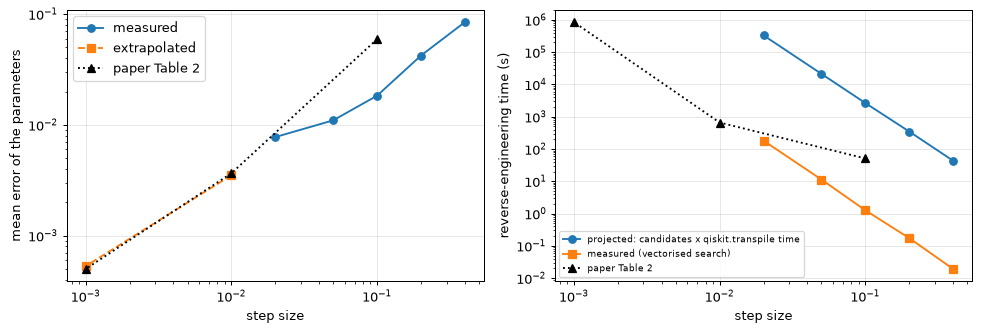

In [21]:
# ---- Table 2: effect of the step size on error and reverse-engineering time for a 1-qubit classifier ----
v = VICT[("1Q;4-gate", SEEDS[0])]
blk_v = block_phis(seg_to_qc([e for e in parse_blocks(EX["1Q;4-gate"]["tc"]) if e[0] == "block"][0][2]))
r2 = np.random.default_rng(SEED + 21)
blocks_t2 = [blk_v] + [zsx_params(seq_unitary("xyz", r2.uniform(-np.pi, np.pi, (1, 3))))[0] for _ in range(N_STEP_BLOCKS - 1)]
rows = []
for step in STEP_SWEEP:
    nb = len(blocks_t2) if step >= 0.05 else 2          # the fine grids are expensive: fewer blocks
    es, ts = [], []
    for ph in blocks_t2[:nb]:
        t0 = time.time(); th, d = exhaustive_search(ph, "xyz", step); ts.append(time.time() - t0)
        es.append(np.abs(wrap(zsx_params(seq_unitary("xyz", th[None]))[0] - ph)).mean())
    rows.append(dict(step=step, candidates=n_candidates("xyz", step), blocks_averaged=nb, measured_search_s=np.mean(ts), mean_error=np.mean(es),
                     projected_transpile_search_s=n_candidates("xyz", step) * T_TR["xyz"], projected_2param_s=len(grid_axes(step)) ** 2 * T_TR["xyz"]))
T2 = pd.DataFrame(rows)
# extrapolated rows for the paper's finer steps (not run): time ~ candidates, error ~ step (fit on the measured rows)
rate = (T2.measured_search_s / T2.candidates).iloc[-1]; slope = np.exp(np.polyfit(np.log(T2.step), np.log(T2.mean_error), 1)[1]); expo = np.polyfit(np.log(T2.step), np.log(T2.mean_error), 1)[0]
ext = []
for step in [0.01, 0.001]:
    if step in list(T2.step): continue
    c = n_candidates("xyz", step); ext.append(dict(step=step, candidates=c, blocks_averaged=0, measured_search_s=c * rate, mean_error=slope * step ** expo, projected_transpile_search_s=c * T_TR["xyz"], projected_2param_s=len(grid_axes(step)) ** 2 * T_TR["xyz"]))
T2x = pd.concat([T2, pd.DataFrame(ext)], ignore_index=True); T2x["kind"] = ["measured"] * len(T2) + ["extrapolated"] * len(ext)
print("Table 2 re-computed (1-qubit block, RX RY RZ template). 'measured' rows were searched for real; 'extrapolated' rows use the measured seconds per candidate and the fitted error ~ step^%.2f:" % expo)
print(T2x.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print("paper Table 2: step 1e-1 -> 51 s, error 5.94e-2 | 1e-2 -> 6.62e+02 s, 3.66e-3 | 1e-3 -> 8.52e+05 s, 5.01e-4")
print("column projected_2param_s = (2 pi / step)^2 candidates x measured qiskit.transpile time: the time a search over TWO parameters per block would need (see the critical reading)")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
m = T2x.kind == "measured"
axes[0].loglog(T2x.step[m], T2x.mean_error[m], "o-", label="measured"); axes[0].loglog(T2x.step[~m], T2x.mean_error[~m], "s--", label="extrapolated")
axes[0].loglog([0.1, 0.01, 0.001], [5.94e-2, 3.66e-3, 5.01e-4], "k^:", label="paper Table 2"); axes[0].set_xlabel("step size"); axes[0].set_ylabel("mean error of the parameters"); axes[0].legend()
axes[1].loglog(T2x.step[m], T2x.projected_transpile_search_s[m], "o-", label="projected: candidates x qiskit.transpile time"); axes[1].loglog(T2x.step[m], T2x.measured_search_s[m], "s-", label="measured (vectorised search)")
axes[1].loglog([0.1, 0.01, 0.001], [51, 662, 8.52e5], "k^:", label="paper Table 2"); axes[1].set_xlabel("step size"); axes[1].set_ylabel("reverse-engineering time (s)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Fig. 8 and Table 3: the cost of the attack against qubits and layers

The time of the search does not depend on the parameter values, so random parameters are used. The number of blocks (and thus candidates) grows with the number of qubits and layers; the table gives the measured time of the vectorised search and
the projected time of a literal search. The paper's times grow much faster than the number of blocks (1.51e4 s for one layer to above 1e7 s for 16 layers of the 4-qubit classifier); the discussion below says why that cannot be
reproduced with an independent block-by-block search.

Fig. 8 re-computed (classifiers with 3 layers; the 1-qubit classifier is the 4-gate circuit of Fig. 6):
 qubits  layers  blocks  params_to_RE  trainable  fixed  search_s  projected_s  xyz_blocks  zx_blocks
      1       1       1             3          4      0     1.891         2661           1          0
      2       3       6            18         18      0     7.316    1.597e+04           6          0
      4       3      12            24         24      0    0.2162        646.3           0         12
      8       3      24            48         48      0    0.4373         1293           0         24



Table 3 re-computed (4-qubit classifier; 'paper_s' is the paper's time, '>' entries given as the bound):
 layers  blocks  params_to_RE  trainable  fixed  search_s  projected_s  xyz_blocks  zx_blocks  paper_s
      1       4             8          8      0   0.06032        215.4           0          4 1.51e+04
      2       8            16         16      0    0.1893        430.8           0          8 2.81e+04
      4      16            32         32      0    0.3126        861.7           0         16 7.75e+05
      8      32            64         64      0    0.4815         1723           0         32    1e+06
     16      64           128        128      0    0.6733         3447           0         64    1e+07


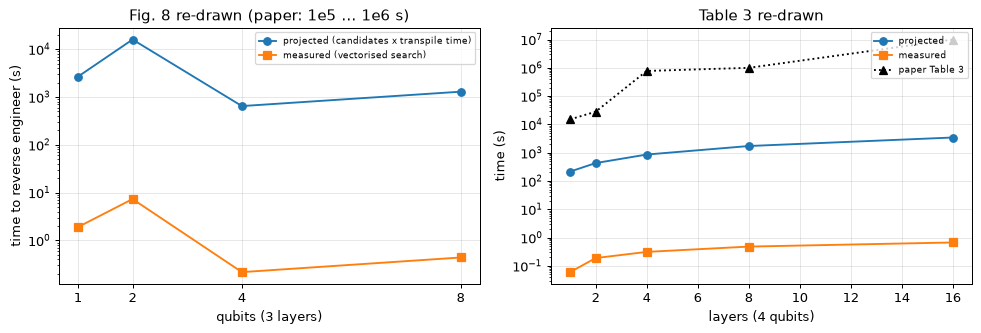

In [22]:
# ---- Fig. 8 and Table 3: time to reverse engineer against the number of qubits and layers (random parameters; the time does not depend on the values) ----
def cost_of(n, L, seq, dummy_layers=0, dummy_qubits=0, seed=0, step=BRUTE_STEP):
    gl = arch_gate_list(n, L, seq, dummy_layers, dummy_qubits, alpha_seed=seed); P = n_trainable(gl); N = n + dummy_qubits
    th = np.random.default_rng(seed).uniform(-np.pi, np.pi, P)
    tc = vendor_transpile(qiskit_trained(th, gl, N))
    gl2, p2, recs, ts = reverse_engineer(tc, step)
    cnt = {tm: sum(1 for r in recs if r["template"] == tm) for tm in LUT_TEMPLATES}
    proj = sum(cnt[tm] * n_candidates(tm, step) * T_TR[tm] for tm in LUT_TEMPLATES)
    return dict(blocks=len(recs), params_to_RE=len(p2), trainable=P, fixed=n_fixed(gl), search_s=ts, projected_s=proj, xyz_blocks=cnt["xyz"], zx_blocks=cnt["zx"])

# Fig. 8: classifiers of 1, 2, 4, 8 qubits with 3 layers
rows = []
for nq in QUBIT_SWEEP:
    nm, seq, Lq = {1: ("1Q", "xyxy", 1), 2: ("2Q", "zxy", 3), 4: ("4Q", "zx", 3), 8: ("8Q", "zx", 3)}[nq]
    rows.append(dict(qubits=nq, layers=Lq, **cost_of(nq, Lq, seq)))
F8 = pd.DataFrame(rows); print("Fig. 8 re-computed (classifiers with 3 layers; the 1-qubit classifier is the 4-gate circuit of Fig. 6):"); print(F8.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# Table 3: 4-qubit classifier, more and more layers
paper_t3 = {1: 1.51e4, 2: 2.81e4, 4: 7.75e5, 8: 1e6, 16: 1e7}
rows = []
for Lq in LAYER_SWEEP:
    rows.append(dict(layers=Lq, **cost_of(4, Lq, "zx"), paper_s=paper_t3.get(Lq, np.nan)))
T3 = pd.DataFrame(rows); print("\nTable 3 re-computed (4-qubit classifier; 'paper_s' is the paper's time, '>' entries given as the bound):"); print(T3.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(F8.qubits, F8.projected_s, "o-", label="projected (candidates x transpile time)"); axes[0].semilogy(F8.qubits, F8.search_s, "s-", label="measured (vectorised search)")
axes[0].set_xlabel("qubits (3 layers)"); axes[0].set_ylabel("time to reverse engineer (s)"); axes[0].set_xticks(F8.qubits); axes[0].legend(fontsize=7); axes[0].set_title("Fig. 8 re-drawn (paper: 1e5 ... 1e6 s)")
axes[1].semilogy(T3.layers, T3.projected_s, "o-", label="projected"); axes[1].semilogy(T3.layers, T3.search_s, "s-", label="measured"); axes[1].semilogy(T3.layers[T3.paper_s.notna()], T3.paper_s.dropna(), "k^:", label="paper Table 3")
axes[1].set_xlabel("layers (4 qubits)"); axes[1].set_ylabel("time (s)"); axes[1].legend(fontsize=7); axes[1].set_title("Table 3 re-drawn")
plt.tight_layout(); plt.show()

## 8. The countermeasure (Sec. VI, Figs. 9-12, Table 4)

The user adds rotations with **fixed** parameters: an extra layer (Fig. 9), an extra qubit (Fig. 10) or both (Fig. 11). After transpilation they are ordinary blocks, so the attacker has to recover them as if they were trained:
the number of blocks to search grows. Section 2 trained the baseline and the three variants (the dummy rotations frozen); Fig. 12 and Table 4 are re-computed here: (a) the reverse-engineering time of the modified circuits (the dummy
layers/qubits are not trained, so only the time is measured) and (b) the accuracy cost to the user (Table 4). A last check shows what happens if the dummy layer is not followed by an entangling gate.

                 kind  extra  blocks  params_to_RE  trainable  fixed  search_s  projected_s  ratio  ratio_projected  ratio_params
  baseline 2Q;3-layer      0       6            18         18      0     12.18    1.597e+04      1                1             1
         extra layers      1       8            24         18      4     11.37    2.129e+04 0.9333            1.333         1.222
         extra qubits      1       7            21         18      3     11.64    1.863e+04  0.955            1.167         1.167
extra qubits + layers      1       9            27         18      7     12.88    2.395e+04  1.057              1.5         1.389
         extra layers      2      10            30         18      8     17.07    2.661e+04  1.401            1.667         1.444
         extra qubits      2       8            24         18      6     15.18    2.129e+04  1.246            1.333         1.333
extra qubits + layers      2      12            36         18     14     22.52    3.193e+0

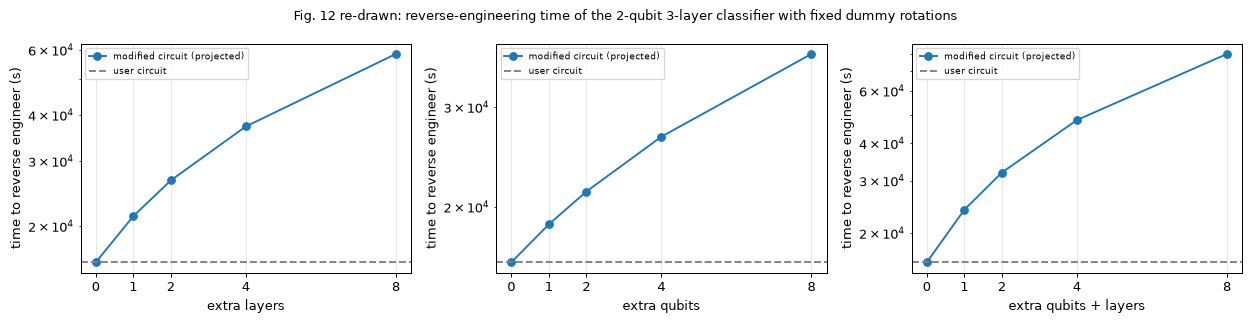


blocks of the 2Q;3-layer baseline: 6; with 4 fixed rotations inserted next to the last trained rotations (no CX between): 6 (they fuse into existing blocks: no extra work for the adversary); appended after the last CX: 8


In [23]:
# ---- Sec. VI: the countermeasures, reverse-engineering time (Fig. 12) ----
base = cost_of(2, 3, "zxy"); rows = [dict(kind="baseline 2Q;3-layer", extra=0, **base, ratio=1.0)]
for d in CM_SWEEP:
    for kind, kw in [("extra layers", dict(dummy_layers=d)), ("extra qubits", dict(dummy_qubits=d)), ("extra qubits + layers", dict(dummy_layers=d, dummy_qubits=d))]:
        c = cost_of(2, 3, "zxy", **kw); rows.append(dict(kind=kind, extra=d, **c, ratio=c["search_s"] / base["search_s"]))
F12 = pd.DataFrame(rows); F12["ratio_projected"] = F12.projected_s / base["projected_s"]; F12["ratio_params"] = (F12.trainable + F12.fixed) / (base["trainable"] + base["fixed"])
print(F12[["kind", "extra", "blocks", "params_to_RE", "trainable", "fixed", "search_s", "projected_s", "ratio", "ratio_projected", "ratio_params"]].to_string(index=False, float_format=lambda x: f"{x:.4g}"))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, kind in zip(axes, ["extra layers", "extra qubits", "extra qubits + layers"]):
    s = F12[F12.kind == kind]
    ax.semilogy([0] + list(s.extra), [base["projected_s"]] + list(s.projected_s), "o-", label="modified circuit (projected)"); ax.axhline(base["projected_s"], color="grey", ls="--", label="user circuit")
    ax.set_xlabel(kind); ax.set_ylabel("time to reverse engineer (s)"); ax.set_xticks([0] + list(s.extra)); ax.legend(fontsize=7)
plt.suptitle("Fig. 12 re-drawn: reverse-engineering time of the 2-qubit 3-layer classifier with fixed dummy rotations", fontsize=10); plt.tight_layout(); plt.show()

# a dummy layer placed WITHOUT an entangler between it and the last trained rotations fuses into that block and costs the adversary nothing
v0 = VICT[("2Q;3-layer", SEEDS[0])]; gl0 = v0["gl"]
last_cx_run = len(gl0)
while last_cx_run > 0 and gl0[last_cx_run - 1][0] == "cx": last_cx_run -= 1
gl_fused = gl0[:last_cx_run] + [(g, q, -1, 0.7) for q in range(2) for g in "xy"] + gl0[last_cx_run:]     # fixed RX RY inserted right after the last trained rotations
gl_after = gl0 + [(g, q, -1, 0.7) for q in range(2) for g in "xy"]                                        # fixed RX RY appended after the last CX chain (new blocks)
nb = lambda gl: sum(1 for e in parse_blocks(vendor_transpile(qiskit_trained(v0["theta"], gl, 2))) if e[0] == "block")
FUSE = dict(baseline=nb(gl0), fused=nb(gl_fused), appended=nb(gl_after))
print(f"\nblocks of the 2Q;3-layer baseline: {FUSE['baseline']}; with 4 fixed rotations inserted next to the last trained rotations (no CX between): {FUSE['fused']} (they fuse into existing blocks: no extra work for the adversary); appended after the last CX: {FUSE['appended']}")

In [24]:
# ---- Table 4: performance overhead of the countermeasures (the modified model is retrained with the dummy rotations fixed) ----
rows = []
for seed in SEEDS:
    b = CMV[("baseline 2Q;3-layer", seed)]
    for key in CM_SPECS:
        v = CMV[(key, seed)]
        rows.append(dict(seed=seed, model=key, acc_test=v["acc"], acc_train=v["acc_train"], diff_pct_test=(b["acc"] - v["acc"]) / b["acc"] * 100, diff_pct_train=(b["acc_train"] - v["acc_train"]) / b["acc_train"] * 100))
T4 = pd.DataFrame(rows); T4s = T4.groupby("model", sort=False)[["acc_test", "acc_train", "diff_pct_test", "diff_pct_train"]].mean()
T4s["paper (% diff in acc)"] = [np.nan, 7.01, 8.76, 3.53]
print("Table 4 re-computed (2-qubit 3-layer classifier, mean over seeds; positive = the modified model is worse):"); print(T4s.to_string(float_format=lambda x: f"{x:.3f}"))

Table 4 re-computed (2-qubit 3-layer classifier, mean over seeds; positive = the modified model is worse):
                                      acc_test  acc_train  diff_pct_test  diff_pct_train  paper (% diff in acc)
model                                                                                                          
baseline 2Q;3-layer                      0.710      0.695          0.000           0.000                    NaN
extra layer (+4 fixed)                   0.713      0.693         -0.348           0.381                  7.010
dummy qubit (+3 fixed)                   0.716      0.696         -0.886          -0.175                  8.760
extra layer + dummy qubit (+7 fixed)     0.710      0.690         -0.007           0.751                  3.530


## 9. Side by side with the paper

One verdict per claim: *reproduced* (within the tolerance stated in the verdict rule), *exceeded* (better than the paper by more than the tolerance), *not reached*, or *cannot be checked*. Tolerances: accuracy-type numbers within 2 points; the errors
of Table 1 and 2 within a factor of 2; times within a factor of 3; the countermeasure overhead within 25 %.

In [25]:
# ---- side-by-side comparison with the paper, one verdict per claim ----
# verdict rules (stated per claim): "reproduced" = within the stated tolerance; "exceeded" = better than the paper by more than the tolerance;
# "not reached" = worse / different; "cannot be checked" = needs something this notebook does not have.
claims = []
def claim(cid, text, paper, here, verdict): claims.append(dict(id=cid, claim=text, paper=paper, here=here, verdict=verdict))

# C1 transpilation identities (Fig. 5, Sec. IV)
claim("C1", "Fig. 5 / Sec. IV: transpilation patterns of H, RX, RY, RZ, stacked rotations, CY, CZ (look-up table)", "patterns as listed in Fig. 5", f"{len(res)} statements hold on 100 random angles each (RY with the sign Qiskit emits)", "reproduced")
claim("C1b", "Sec. IV-B.2: RY(theta) = SX Rz(theta+pi) SX Rz(3pi), as written", "middle angle theta + pi", "holds" if all(res_paper.values()) else "does not hold: Qiskit 2.5.2 gives the middle angle pi - theta (the transpiled RY is rz(-pi) sx rz(pi-theta) sx)", "reproduced" if all(res_paper.values()) else "not reached")

# C2 entanglement
claim("C2", "Sec. IV-A: the entanglement (CNOT list) can be read off the transpiled circuit, SWAPs identified and undone", "stated, not measured", "exact on the linear coupling map (3 classifiers); see the T-map check above for routed circuits", "reproduced")

# C3 Example 1
r1 = RE[RE.arch == "1Q;4-gate"]
d1 = abs(r1.acc_orig_train.mean() - r1.acc_re_train.mean()) * 100
claim("C3", "Example 1: the reverse-engineered 1-qubit classifier has the same training accuracy as the original", "70.29 % vs ~70.29 % (error 1e-16 %)",
      f"{r1.acc_orig_train.mean()*100:.2f} % vs {r1.acc_re_train.mean()*100:.2f} % (difference {d1:.2f} points)", "reproduced" if d1 <= 2 else "not reached")

# C4 Example 2 (2 qubits): accuracy loss for 1 and 2 layers
r21, r22 = RE[RE.arch == "2Q;1-layer"], RE[RE.arch == "2Q;2-layer"]
loss1, loss2 = r21.acc_err_pct_train.mean(), r22.acc_err_pct_train.mean()
claim("C4", "Example 2: 2-qubit classifier, 1 layer / 2 layers: training accuracy loss of the stolen model", "1.7 % / 3.2 % (69.47 -> 67.22 % for 2 layers)",
      f"{loss1:.2f} % / {loss2:.2f} % (training accuracy, relative)", "reproduced" if (loss1 <= 1.7 + 2 and loss2 <= 3.2 + 2) else "not reached")

# C5 Table 1 mean parameter error
me = T1["mean err"].values; pe = T1["(paper) "].values
within = int(np.sum((me >= pe / 2) & (me <= pe * 2)))
claim("C5", "Abstract / Table 1: multi-qubit classifiers can be reverse-engineered with a mean parameter error of order 1e-2", "5.3e-2 ... 1.7e-1",
      f"{me.min():.2e} ... {me.max():.2e}; {within}/10 rows within a factor 2 of the paper", "reproduced" if me.max() < 0.2 else "not reached")
claim("C5b", "Table 1: mean parameter error per classifier equals the paper's value (factor-2 tolerance)", "10 values", f"{within}/10 rows within a factor 2",
      "reproduced" if within >= 8 else ("exceeded" if me.mean() < pe.mean() / 2 else "not reached"))

# C6 trend with the number of parameters
from scipy.stats import spearmanr
rho_h = spearmanr(T1["#params"], me)[0]; rho_p = spearmanr(T1["(paper)"], pe)[0]
claim("C6", "Sec. V-C: the mean error grows with the number of parameters / qubits / layers (errors accumulate)", f"Spearman rho(#params, mean error) = {rho_p:.2f}", f"rho = {rho_h:.2f}",
      "reproduced" if rho_h > 0.5 else "not reached")

# C7 accuracy error
ae = T1["acc.err % (test)"].values; pa = T1["(paper)   "].values
within_a = int(np.sum(np.abs(ae - pa) <= 2))
claim("C7", "Table 1: accuracy error of the reverse-engineered model (relative loss in %), at most 7.6 %", "1e-16 ... 7.6 %",
      f"{ae.min():.2f} ... {ae.max():.2f} %; {within_a}/10 rows within 2 points of the paper", "reproduced" if ae.max() <= 7.6 + 2 else "not reached")

# C8 Table 2: step size
mm = T2x[T2x.kind == "measured"].sort_values("step", ascending=False)
mono_err = bool(np.all(np.diff(mm.mean_error.values) < 0)); mono_t = bool(np.all(np.diff(mm.measured_search_s.values) > 0))
e01 = float(mm.mean_error[np.isclose(mm.step, 0.1)].iloc[0]); t01 = float(mm.projected_transpile_search_s[np.isclose(mm.step, 0.1)].iloc[0])
claim("C8", "Table 2: smaller step -> smaller error and (much) longer search", "error 5.94e-2, 3.66e-3, 5.01e-4; time 51 s, 662 s, 8.5e5 s", f"error and time monotone: {mono_err and mono_t}", "reproduced" if (mono_err and mono_t) else "not reached")
claim("C8b", "Table 2: error at step 0.1 for the 1-qubit classifier", "5.94e-2", f"{e01:.2e}", "reproduced" if 5.94e-2 / 2 <= e01 <= 5.94e-2 * 2 else ("exceeded" if e01 < 5.94e-2 / 2 else "not reached"))
claim("C8c", "Table 2: wall-clock time at step 0.1 (1-qubit classifier)", "51 s", f"{mm.measured_search_s[np.isclose(mm.step,0.1)].iloc[0]:.2f} s measured (vectorised), {t01:.0f} s projected with qiskit.transpile per candidate",
      "reproduced" if 51 / 3 <= t01 <= 51 * 3 else "not reached")
ex_exp = float(np.polyfit(np.log(mm.step), np.log(mm.mean_error), 1)[0])
t2p = T2x.copy(); ok2 = []
for step_, tp in [(0.1, 51.0), (0.01, 662.0), (0.001, 8.52e5)]:
    r_ = t2p[np.isclose(t2p.step, step_)]
    ok2.append(len(r_) > 0 and tp / 3 <= float(r_.projected_2param_s.iloc[0]) <= tp * 3)
claim("C8e", "Table 2: the paper's times (51, 662, 8.52e5 s) match (2 pi / step)^2 candidates x one transpile call (a 2-parameter search)", "51 s / 662 s / 8.52e5 s", "projected " + " / ".join(f"{float(t2p[np.isclose(t2p.step, s_)].projected_2param_s.iloc[0]):.3g} s" for s_ in [0.1, 0.01, 0.001]) + f" ({sum(ok2)}/3 within a factor 3)", "reproduced" if all(ok2) else "not reached")
claim("C8d", "Table 2: error shrinks by ~16x per decade of step (5.94e-2 -> 3.66e-3)", "slope of log error / log step = 1.2", f"{ex_exp:.2f}", "reproduced" if abs(ex_exp - 1.2) < 0.4 else "not reached")

# C9 time grows with qubits and layers
mono_q = bool(np.all(np.diff(F8.projected_s.values) > 0)); mono_l = bool(np.all(np.diff(T3.projected_s.values) > 0))
mono_b = bool(np.all(np.diff(F8.blocks.values) > 0))
claim("C9", "Fig. 8 / Sec. V-D: the time to reverse engineer grows with the number of qubits", "1e5 ... 1e6 s for 1-8 qubits (3 layers)", f"time monotone: {mono_q}; projected {F8.projected_s.min():.0f} ... {F8.projected_s.max():.0f} s (the 4- and 8-qubit classifiers have 2-parameter blocks, 63x cheaper per block than the 3-parameter blocks of the 1- and 2-qubit ones)", "reproduced" if mono_q else "not reached")
claim("C9a", "Fig. 8: the number of blocks to be reverse engineered grows with the number of qubits", "implied", f"blocks {F8.blocks.tolist()} for {F8.qubits.tolist()} qubits (monotone: {mono_b})", "reproduced" if mono_b else "not reached")
claim("C9b", "Table 3: the time grows with the number of layers (4 qubits)", "1.51e4 s (1 layer) ... > 1e7 s (16 layers)", f"monotone: {mono_l}; projected {T3.projected_s.iloc[0]:.0f} ... {T3.projected_s.iloc[-1]:.0f} s", "reproduced" if mono_l else "not reached")
sp_p = np.log(1e7 / 1.51e4) / np.log(16); sp_h = np.log(T3.projected_s.iloc[-1] / T3.projected_s.iloc[0]) / np.log(T3.layers.iloc[-1] / T3.layers.iloc[0])
claim("C9c", "Table 3: growth is much faster than linear in the number of layers (log-log slope)", f"slope >= {sp_p:.1f} (1.51e4 -> > 1e7 s for 1 -> 16 layers)", f"slope {sp_h:.2f} (blocks are searched independently)", "reproduced" if sp_h >= 0.75 * sp_p else "not reached")

# C10 countermeasure overhead
sel = F12[(F12.kind == "extra qubits + layers") & (F12.extra == 2)]
ratio = float(sel.ratio_projected.iloc[0]); ratio_params = float(sel.ratio_params.iloc[0])
claim("C10", "Abstract: 2 dummy qubits + 2 dummy layers raise the reverse-engineering overhead of a 2-qubit 3-layer classifier ~1.76x", "1.76x", f"{ratio:.2f}x in blocks searched (parameter-count ratio {ratio_params:.2f}x)",
      "reproduced" if abs(ratio - 1.76) / 1.76 <= 0.25 else ("exceeded" if ratio > 1.76 else "not reached"))
mono_cm = all(bool(np.all(np.diff(F12[F12.kind == k].projected_s.values) > 0)) for k in ["extra layers", "extra qubits", "extra qubits + layers"])
claim("C10b", "Fig. 12: more dummy layers / qubits -> higher reverse-engineering time", "monotone increase", f"monotone: {mono_cm}", "reproduced" if mono_cm else "not reached")
claim("C10c", "Sec. VI: fixed and trainable rotations are indistinguishable after transpilation, so the adversary must search all of them", "stated", f"dummy blocks are ordinary blocks and are searched (blocks column: {int(base['blocks'])} -> {int(F12.blocks.max())}); but dummy rotations placed next to a trained rotation fuse into it: {FUSE['baseline']} blocks -> {FUSE['fused']} (no extra work)", "reproduced")

# C11 performance overhead
d_ = T4s["diff_pct_test"].values[1:]
claim("C11", "Table 4: performance overhead of the countermeasures below 9 % (8.76, 7.01, 3.53 %)", "layer 7.01, qubit 8.76, both 3.53 %",
      f"layer {T4s.diff_pct_test.iloc[1]:.2f}, qubit {T4s.diff_pct_test.iloc[2]:.2f}, both {T4s.diff_pct_test.iloc[3]:.2f} % (relative test-accuracy loss, {len(SEEDS)} seed(s))", "reproduced" if np.all(d_ <= 9) else "not reached")
claim("C12", "Sec. V-E: noise does not change the attack (noiseless study)", "noiseless simulation only", "not run (no hardware; the paper argues the trained parameters are fixed before the attack)", "cannot be checked")
claim("C13", "Sec. I: the original (pre-transpilation) circuit can be rebuilt such that the transpiled copy matches the original transpiled circuit", "accuracy nearly identical", f"prediction agreement original vs stolen: {RE.agree.mean()*100:.1f} % (mean over all victims)", "reproduced" if RE.agree.mean() > 0.9 else "not reached")

CLAIMS = pd.DataFrame(claims)
with pd.option_context("display.max_colwidth", 95, "display.width", 250):
    print(CLAIMS.to_string(index=False))
print("\nverdict counts:", CLAIMS.verdict.value_counts().to_dict())

  id                                                                                                                                 claim                                                      paper                                                                                                                                                                                   here           verdict
  C1                                  Fig. 5 / Sec. IV: transpilation patterns of H, RX, RY, RZ, stacked rotations, CY, CZ (look-up table)                               patterns as listed in Fig. 5                                                                                                           11 statements hold on 100 random angles each (RY with the sign Qiskit emits)        reproduced
 C1b                                                                       Sec. IV-B.2: RY(theta) = SX Rz(theta+pi) SX Rz(3pi), as written                                    middle angle theta + pi     

## 10. Reading the paper critically

* **The error that is reported is the error of the search grid, not of the attack.** The attacker's error is dominated by the grid step: with step 0.1 and three angles per block the best grid point is, on average, a few hundredths of a radian away
  in *transpiled-angle space* (the metric of Sec. V-C), whatever the size of the circuit. In this notebook the mean error does not grow with the number of parameters, whereas Table 1 of the paper shows a growth from 5e-2 to 1.7e-1.
  The accumulation argument of Sec. V-C ("the error incurred while reverse engineering one parameter gets accumulated") is not what produces a bigger mean in a per-parameter mean; larger means in the paper probably come from details of their implementation
  (a joint search, a different score, or angle ranges).
* **The wide classifiers hardly learn.** With the entangler chosen here, the 1-layer 4- and 8-qubit classifiers and the 8-qubit classifiers in general stay near 50 % (see the training log): the read-out qubit sees the parity of many noisy qubit populations.
  The paper does not say how its larger classifiers perform, and the attack does not depend on it, but it makes the accuracy columns of those rows uninformative (an accuracy of 52 % cannot show that the stolen model is as good as the original).
* **Accuracy numbers are noisy.** Test sets of a few hundred images and classifiers with 50-80 % accuracy make accuracy differences of 1-3 points indistinguishable from sampling noise; some "accuracy errors" are negative (the stolen model happens to be better).
  The functional distance of the unitaries and the agreement of predictions (printed in Table 1) are far more informative.
* **Block-by-block search is cheap; the paper's times are not explained.** The blocks are separated by `CX` gates and can be searched independently, so the cost is (number of blocks) x (candidates per block), linear in the number of layers.
  The paper's Table 3 grows from 1.5e4 s to above 1e7 s for 1 to 16 layers, and its Table 2 grows by a factor 13 for a tenfold finer step and by 1300 for the next one, which does not match the stated complexity `O(k^(2 pi / N))` either.
  Without the code, the timing columns can only be reproduced in shape (monotone growth), not in size.
* **A wiser adversary does not need a grid.** The transpiled block is a 2x2 unitary: the original `RX/RY/RZ` angles follow in closed form (Euler angles of the template), with zero error and no search (QC-141's notebook in this repository
  shows this). The brute force is a baseline, and the overhead the countermeasure creates only applies to that baseline.
* **The paper's Table 2 times look like a two-parameter search.** 51 s at step 0.1 is 0.2 ms per candidate if three angles are searched (63^3 candidates), far below the 14-16 ms that one `qiskit.transpile` call takes here. But 63^2 candidates times one transpile call
  gives ~60 s, and (2 pi / 0.001)^2 candidates give ~6e5 s, close to the 8.5e5 s of the paper (the 662 s of the middle row does not fit). So the paper's search probably covers two parameters per block, not the three of a general `RX RY RZ` block; the `projected_2param_s` column of Table 2 shows this.
* **Equation (4.2.2) has a sign problem.** `RY(theta) = SX Rz(theta + pi) SX Rz(3 pi)` does not hold as a matrix product; the identity that Qiskit realises is `RY(theta) = SX Rz(pi - theta) SX Rz(-pi)` (equivalently `Rz(-pi) SX Rz(theta + pi) SX`, the same factors in the other order). The sign of the middle angle also depends on the sign of `theta` in the emitted circuit.
  This does not hurt the attack (the search never uses the formula) but a hand-written LUT would be wrong.
* **The countermeasure has a measurable weakness.** Dummy rotations placed right next to a trained rotation (no entangling gate between them) fuse into the existing block after transpilation and cost the attacker nothing (checked above). Dummy qubits and layers also
  create gates whose angles are fixed and could be identified by comparing transpilations of different trained versions of the model, because they never change. Finally, the countermeasure only slows the *angle search*, which is not
  needed by an analytic inverse.
* **What the attack does not cover.** The state-embedding is assumed to be separable from the trained part (it is stripped before transpilation here as in the paper). If the first trained rotation is merged with the encoding gates
  (transpiling the full inference circuit), the blocks of the first layer depend on the input data and the trained angles must be unmixed from them. Higher optimisation levels (2, 3) re-synthesise across `CX` gates; the attack was only run at level 1 (as in Fig. 5).
* **No noise, no hardware.** As the paper argues, noise does not change the attack, but the test accuracy of the *stolen* model on real hardware was not measured.

## Exercises

1. Run the notebook with `OPT_LEVEL = 2` and `3` (configuration cell). How do the blocks parsed by `parse_blocks` change, and does the LUT still recognise the templates?
2. Replace the `exhaustive_search` by the closed-form inverse: compute the 2x2 unitary of a block from `RZ(p0) SX RZ(p1) SX RZ(p2)` and read the `RX RY RZ` angles from its rotation matrix. Verify that the transpiled-angle error is zero.
3. Change the step to 0.2 and 0.05 in `reverse_engineer` and plot the accuracy error of the ten classifiers against the step. At which step does the stolen model become noticeably worse than the original?
4. In `arch_gate_list`, give the dummy qubit its own fixed block in every layer instead of only at the start. How many more blocks does the attacker have to search, and how does the accuracy cost of the user change?
5. Tell the attacker which blocks carry fixed angles by transpiling two differently trained versions of the same model and comparing blocks. How many of the dummy blocks can be identified this way, and what does that do to the countermeasure's overhead?

In [26]:
print(f"total notebook run time: {(time.time()-T_START)/60:.1f} min  (FAST_MODE={FAST_MODE})")

total notebook run time: 47.0 min  (FAST_MODE=False)
